In [1]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

## reduced second virial coefficient
from dataclasses import dataclass
from scipy.optimize import brentq
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import LeaveOneOut, cross_val_score

## plotting
from mpl_toolkits.mplot3d import Axes3D
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import PolynomialFeatures
from matplotlib.colors import to_rgba
from matplotlib.lines import Line2D
from sklearn.pipeline import make_pipeline

import matplotlib.colors as mcolors
from scipy.stats import gaussian_kde

In [2]:
data_path = 'bimodal_phase-diagram/data'

R_S = 1
R_L = 2

# sim variables for diffusion time conversion
dt_Integration = 1e-3                       # simulation timestep
period = 10_000                             # simulation recording interval
N_timesteps = 2_000_000                     # number of timesteps
sim_eta0 = 0.3                              # solvent viscosity parameter
sim_rho = 3                                 # number density (multiply by mass units for [mass]/[length]^3)
sim_kT = 0.1                                # unit of energy/temperature

out_path = 'phase-diagram-dynamics'

compositions = ['100-0', '75-25', '50-50', '25-75', '0-100']
phi_L_vals = [0, 0.25, 0.5, 0.75, 1.0]
comp_color_list = ['#17A8A8', '#4E7FC9', '#7E54A3', '#B23A6A', '#CD0000']
comp_mark_dataset = ['d', 'p', '>', 'D', '*']

phi_vals = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30]
phi_labels = ['05', '10', '15', '20', '25', '30']
phi_mark_list = ['d', 'p', '>', 'D', '*', 'X']

D0_vals = [3, 5, 7, 9, 12]
D0_labels = ['03', '05', '07', '09', '12']
D0_color_list = ['red', 'blue', 'green', 'hotpink', 'grey']
D0_mark_list = ['d', 'p', '*', 'D', 'X']

### Load and process main data : includes adding reduced second virial coefficient and phase classification

In [3]:
df_parquet = pd.read_parquet(f"{data_path}/phase_diagram_net_data.parquet")
df_parquet.keys()

Index(['phi', 'comp', 'D0', 'kappa', 'network-type', 'frame', 'cut_off',
       'n_components', 'lcc_size', 'ncolloids', 'f_lcc', 'lcc_frac_type1',
       'bond_frac_11', 'bond_frac_12', 'bond_frac_22', 'core2_size',
       'core2_frac_type1', 'n_dangling', 'dangling_frac_type1', 'lcc_span',
       'box_span', 'percolation', 'chi_meanclustersize', 'mean_finite_size',
       'lcc_extent_x', 'lcc_extent_y', 'lcc_extent_z', 'max_axis_span',
       'n_axes_spanning', 'avg_degree', 'Zavg_Z_any', 'Zavg_Z_11', 'Zavg_Z_12',
       'Zavg_Z_21', 'Zavg_Z_22', 'Zavg_Z_1any', 'Zavg_Z_2any', 'msd_colloid',
       'msd_coll_smplstddev', 'msd_colloid_1', 'msdc1_smplstddev',
       'msd_colloid_2', 'msdc2_smplstddev'],
      dtype='object')

#### Add phi_L

In [4]:
#for comp in compositions:
#    print(float(comp.split('-')[1])/100)

phiL_val_list = []
for x in df_parquet['comp'].to_numpy():
    phiL_val_list.append(float(x.split('-')[1])/100)
df_parquet['phi_L'] = phiL_val_list

#### Add second virial coefficient

In [5]:
r"""
Effective reduced second virial coefficient B2*_eff for a bimodal gel
B2* is computed directly from the Morse potential

Morse pair potential (minimum at contact r_e = sigma_ij):
    U_ij(r) = D0_ij [ exp(-2 alpha (r - sigma_ij)) - 2 exp(-alpha (r - sigma_ij)) ]
    U_ij(sigma_ij) = -D0_ij   (well depth)

R_S = 1.0, R_L = 2.0      (small/large radii; size ratio 2)
sigma_ij = R_i + R_j  ->  SS=1.0, SL=1.5, LL=2.0  the pair contact distance
D0_ij = D0_base * sigma_ij  with D0_base = 12 kT
        ->  D0_SS=12, D0_SL=18, D0_LL=24 kT
alpha = 60  (same range parameter for all pairs)
"""

_trapz = np.trapezoid if hasattr(np, "trapezoid") else np.trapz

# ----------------------------------------------------------------------
# Morse potential
# ----------------------------------------------------------------------
def beta_U_morse(r, R_i, R_j, D0_base, alpha):
    """beta * U_ij(r) for the Morse pair, depth scaled as D0_ij = D0_base*sigma_ij."""
    r = np.asarray(r, dtype=float)
    sigma = R_i + R_j                 # contact distance = minimum location r_e
    D0 = D0_base * sigma             # per-pair depth (in kT)
    t = alpha * (r - sigma)
    # clip the repulsive exponent so exp() cannot overflow (caps the hard wall)
    a2 = np.clip(-2.0 * t, -700, 700)
    a1 = np.clip(-1.0 * t, -700, 700)
    return D0 * (np.exp(a2) - 2.0 * np.exp(a1))


def barker_henderson_diameter(R_i, R_j, D0_base, alpha, n=20000):
    """Effective hard-sphere (Barker-Henderson) diameter of the repulsive core.
    d = \int_0^{r_e} (1 - exp(-beta u0)) dr with u0 the WCA-split repulsion."""
    sigma = R_i + R_j
    r = np.linspace(1e-6, sigma, n)
    bU = beta_U_morse(r, R_i, R_j, D0_base, alpha)
    D0 = D0_base * sigma
    u0 = bU + D0                      # shift so the minimum value is 0
    u0 = np.clip(u0, 0, 700)         # repulsive branch only
    return _trapz(1.0 - np.exp(-u0), r)


# ----------------------------------------------------------------------
# second virial coefficient (computed directly from the Morse potential)
# ----------------------------------------------------------------------
def B2_pair(R_i, R_j, D0_base, alpha, n=60000, ref="sigma"):
    """B2_ij, B2^HS_ij, B2*_ij from the Morse potential.
    ref: 'sigma' uses (2pi/3) sigma^3 as the HS reference;
         'bh'    uses the Barker-Henderson effective diameter."""
    sigma = R_i + R_j
    r_max = sigma + 8.0 / alpha       # well has decayed by here (exp(-8)~3e-4)
    r = np.linspace(1e-6, r_max, n)
    bU = beta_U_morse(r, R_i, R_j, D0_base, alpha)
    u = np.clip(bU, -700, 700)
    integrand = (1.0 - np.exp(-u)) * r ** 2
    B2 = 2.0 * np.pi * _trapz(integrand, r)

    if ref == "bh":
        d = barker_henderson_diameter(R_i, R_j, D0_base, alpha)
    else:
        d = sigma
    B2_HS = (2.0 * np.pi / 3.0) * d ** 3
    return B2, B2_HS, B2 / B2_HS


# ----------------------------------------------------------------------
# composition handling (volume composition -> number fractions; R^3 weighting)
# ----------------------------------------------------------------------
def number_fractions(x_L_vol, R_L, R_S):
    nL = x_L_vol / R_L ** 3
    nS = (1.0 - x_L_vol) / R_S ** 3
    Z = nL + nS
    return nL / Z, nS / Z


# ----------------------------------------------------------------------
# effective B2* via mixing rules
# ----------------------------------------------------------------------
@dataclass
class MorseSystem:
    R_L: float
    R_S: float
    alpha: float
    ref: str = "sigma"

    def pair_B2star(self, D0_base):
        LL = B2_pair(self.R_L, self.R_L, D0_base, self.alpha, ref=self.ref)
        LS = B2_pair(self.R_L, self.R_S, D0_base, self.alpha, ref=self.ref)
        SS = B2_pair(self.R_S, self.R_S, D0_base, self.alpha, ref=self.ref)
        return LL, LS, SS

    def B2star_eff(self, x_L_vol, D0_base, rule="one_fluid"):
        xL, xS = number_fractions(x_L_vol, self.R_L, self.R_S)
        (B2_LL, HS_LL, _), (B2_LS, HS_LS, _), (B2_SS, HS_SS, _) = self.pair_B2star(D0_base)
        sLL = (2 * self.R_L) ** 2
        sLS = (self.R_L + self.R_S) ** 2
        sSS = (2 * self.R_S) ** 2
        if rule == "one_fluid":
            w_LL, w_LS, w_SS = xL * xL, 2 * xL * xS, xS * xS
        elif rule == "contact":
            w_LL, w_LS, w_SS = xL * xL * sLL, 2 * xL * xS * sLS, xS * xS * sSS
        else:
            raise ValueError(rule)
        B2 = w_LL * B2_LL + w_LS * B2_LS + w_SS * B2_SS
        HS = w_LL * HS_LL + w_LS * HS_LS + w_SS * HS_SS
        return B2 / HS


def D0_for_target(system, x_L_vol, target_B2star, rule="one_fluid",
                  lo=0.01, hi=20.0):
    """Find D0_base giving B2*_eff = target at composition x_L (B2* decreases with D0)."""
    f = lambda d: system.B2star_eff(x_L_vol, d, rule=rule) - target_B2star
    if f(lo) * f(hi) > 0:
        return np.nan
    return brentq(f, lo, hi, xtol=1e-5)


# ----------------------------------------------------------------------
# second virial coefficient (computed directly from the Morse potential)
# ----------------------------------------------------------------------
def B2_pair(R_i, R_j, D0_base, alpha, n=60000, ref="sigma"):
    """B2_ij, B2^HS_ij, B2*_ij from the Morse potential.
    ref: 'sigma' uses (2pi/3) sigma^3 as the HS reference;
         'bh'    uses the Barker-Henderson effective diameter."""
    sigma = R_i + R_j
    r_max = sigma + 8.0 / alpha       # well has decayed by here (exp(-8)~3e-4)
    r = np.linspace(1e-6, r_max, n)
    bU = beta_U_morse(r, R_i, R_j, D0_base, alpha)
    u = np.clip(bU, -700, 700)
    integrand = (1.0 - np.exp(-u)) * r ** 2
    B2 = 2.0 * np.pi * _trapz(integrand, r)

    if ref == "bh":
        d = barker_henderson_diameter(R_i, R_j, D0_base, alpha)
    else:
        d = sigma
    B2_HS = (2.0 * np.pi / 3.0) * d ** 3
    return B2, B2_HS, B2 / B2_HS


R_L, R_S, ALPHA = 2, 1, 60
sysm = MorseSystem(R_L=R_L, R_S=R_S, alpha=ALPHA, ref="sigma")


# ---- precompute per-pair B2 / B2_HS for each unique D0_base (only 5) ----
pair_cache = {}
for d0 in sorted(df_parquet.D0.unique()):
    LL = B2_pair(R_L, R_L, int(d0), ALPHA)
    LS = B2_pair(R_L, R_S, int(d0), ALPHA)
    SS = B2_pair(R_S, R_S, int(d0), ALPHA)
    pair_cache[d0] = dict(LL=LL, LS=LS, SS=SS)

sLL, sLS, sSS = (2*R_L)**2, (R_L+R_S)**2, (2*R_S)**2


def b2star_eff(xL_vol, d0, rule):
    xL, xS = number_fractions(xL_vol, R_L, R_S)
    c = pair_cache[d0]
    (B2_LL, HS_LL, _), (B2_LS, HS_LS, _), (B2_SS, HS_SS, _) = c["LL"], c["LS"], c["SS"]
    if rule == "one_fluid":
        wLL, wLS, wSS = xL*xL, 2*xL*xS, xS*xS
    else:
        wLL, wLS, wSS = xL*xL*sLL, 2*xL*xS*sLS, xS*xS*sSS
    B2 = wLL*B2_LL + wLS*B2_LS + wSS*B2_SS
    HS = wLL*HS_LL + wLS*HS_LS + wSS*HS_SS
    return B2 / HS


def d0_eff(xL_vol, d0, rule):
    xL, xS = number_fractions(xL_vol, R_L, R_S)
    D0_LL, D0_LS, D0_SS = d0*(2*R_L), d0*(R_L+R_S), d0*(2*R_S)
    if rule == "one_fluid":
        wLL, wLS, wSS = xL*xL, 2*xL*xS, xS*xS
    else:
        wLL, wLS, wSS = xL*xL*sLL, 2*xL*xS*sLS, xS*xS*sSS
    return (wLL*D0_LL + wLS*D0_LS + wSS*D0_SS) / (wLL + wLS + wSS)

df_parquet["lnB2_ct"] = [np.log(abs(b2star_eff(x, d, "contact")))   for x, d in zip(df_parquet.phi_L, df_parquet.D0)]

In [6]:
lnB2_ct_vals = pd.unique(df_parquet["lnB2_ct"])
lnB2_ct_vals

array([ 1.96551852,  5.789401  ,  9.60460888, 13.46911316, 19.31707119,
        4.27333259, 11.4203754 , 19.14509156, 27.00120879, 38.85154979,
        5.34601665, 12.8424265 , 20.63210407, 28.49743106, 40.34914891,
        6.17822908, 13.82140296, 21.63357948, 29.50199295, 41.35417006,
        6.99493384, 14.71961523, 22.54320918, 30.41316901, 42.2655758 ])

#### Add diffusion time of average sized particle

In [7]:
def diffusion_time(sim_R_C, dt_Integration, period, N_timesteps, sim_eta0=0.3, sim_rho=3, sim_kT=0.1):

    nframes = int(N_timesteps / period)         # number of frames

    sim_V_C = (4/3)*np.pi*sim_R_C**3            # volume of a sim colloid 
    sim_mass_C = sim_V_C * sim_rho              # mass of a sim colloid [mass]

    # [time]
    sim_D = sim_kT/(6*np.pi*sim_eta0*sim_R_C)   # diffusion coefficient = r^2 / tau
    sim_tau_D = (sim_R_C**2)/(sim_D)            # bare particle diffusion time [time]

    tau_D_frames    = sim_tau_D / (period * dt_Integration)         # τ_D measured in frames
    tau_D_timesteps = sim_tau_D / dt_Integration                    # τ_D measured in timesteps
    
    #print(f' - simulation diffusion time of avg sized colloid: {round(sim_tau_D,3)} sim times ({round(sim_tau_D_dt,3)} timesteps)')
    t1 = period * dt_Integration                # simulation time per frame [time]
    sim_time_tauD = t1/sim_tau_D                # diffusion time per frame
    sim_tau_D_dt = sim_tau_D/dt_Integration

    # the two ways to caluclate total run time in diffusion times should match
    #print(f" - sim ran for {nframes * sim_time_tauD} tau_D")
    #run_time_tauD = N_timesteps / sim_tau_D_dt
    #print(f" * sim ran for {run_time_tauD} tau_D")
    
    return sim_tau_D, tau_D_frames, tau_D_timesteps

tauD_df_list = []
for p, phi in enumerate(phi_vals):
    phi_label = phi_labels[p]
    
    for c, comp in enumerate(compositions):
        phi_L = phi_L_vals[c]
        df = df_parquet.loc[(df_parquet['comp'] == comp) & (df_parquet['phi'] == phi)].copy()

        tau_D_RS, tauD_RS_frames, tauD_dt = diffusion_time(R_S, dt_Integration, period, N_timesteps)
        df['tauD_RS'] = df['frame']/tauD_RS_frames

        tau_D_RL, tauD_RL_frames, tauD_dt = diffusion_time(R_L, dt_Integration, period, N_timesteps)
        df['tauD_RL'] = df['frame']/tauD_RL_frames
        
        df_allc = df.loc[df['network-type'] == 'allc'].copy()
        if not df_allc.empty:
            # NOTE: this is the volume-weighted average "what radius characterizes the typical unit of material/volume"
            avg_R_C = (phi_L*R_L) + ((1-phi_L)*R_S)
            #print(f"phi={phi}, phi_L={phi_L}, avg_R_C={avg_R_C}")
            df_allc['avg_R_C'] = avg_R_C
            
            tau_D, tauD_frames, tauD_dt = diffusion_time(avg_R_C, dt_Integration, period, N_timesteps)
            df_allc['tauD_mean'] = df_allc['frame']/tauD_frames
            tauD_df_list.append(df_allc)

        df_c1 = df.loc[df['network-type'] == 'c1-only'].copy()
        if not df_c1.empty:
            # NOTE: this is the volume-weighted average "what radius characterizes the typical unit of material/volume"
            avg_R_C = R_S
            #print(f"phi={phi}, phi_L={phi_L}, avg_R_C={avg_R_C}")
            df_c1['avg_R_C'] = avg_R_C
            
            tau_D, tauD_frames, tauD_dt = diffusion_time(avg_R_C, dt_Integration, period, N_timesteps)
            df_c1['tauD_mean'] = df_c1['frame']/tauD_frames
            tauD_df_list.append(df_c1)

        df_c2 = df.loc[df['network-type'] == 'c1-only'].copy()
        if not df_c2.empty:
            # NOTE: this is the volume-weighted average "what radius characterizes the typical unit of material/volume"
            avg_R_C = R_S
            #print(f"phi={phi}, phi_L={phi_L}, avg_R_C={avg_R_C}")
            df_c2['avg_R_C'] = avg_R_C
            
            tau_D, tauD_frames, tauD_dt = diffusion_time(avg_R_C, dt_Integration, period, N_timesteps)
            df_c2['tauD_mean'] = df_c2['frame']/tauD_frames
            tauD_df_list.append(df_c2)

        
df_all = pd.concat(tauD_df_list, ignore_index=True)
df_all[['frame','tauD_RS','tauD_RL','tauD_mean']]

,frame,tauD_RS,tauD_RL,tauD_mean
0,0,0.000000,0.000000,0.000000
1,1,0.176839,0.022105,0.176839
2,2,0.353678,0.044210,0.353678
3,3,0.530516,0.066315,0.530516
4,4,0.707355,0.088419,0.707355
...,...,...,...,...
89904,295,52.167454,6.520932,6.520932
89905,296,52.344292,6.543037,6.543037
89906,297,52.521131,6.565141,6.565141
89907,298,52.697970,6.587246,6.587246


#### Helper functions

In [8]:
def final_state(d):
    """last frame per (phi,comp,D0) system."""
    idx = d.groupby(['phi','comp','D0'])['frame'].idxmax()
    return d.loc[idx]

def nearest_b2_match(fs, target_row, tol=0.05):
    """rows within tol of a target lbB2_ct AND same phi (matched phase point)."""
    return fs[(fs['phi'] == target_row['phi']) &
              (np.abs(fs['lbB2_ct'] - target_row['lbB2_ct']) < tol)]

In [9]:
## ISOALTE THE LAST FRAME ONLY
lastframe_df_list = []
for p, phi in enumerate(phi_vals):
    phi_label = phi_labels[p]
    if phi == 0.05:
        filter_compositions = ['100-0', '0-100']
    else:
        filter_compositions = compositions
    for comp in filter_compositions:
        for D0 in D0_vals:
            #print(phi, comp, D0)
            system_df = df_all.loc[(df_all['phi'] == phi) & (df_all['comp'] == comp) & (df_all['D0'] == D0)]
            lastframe_df = system_df.loc[system_df['frame'] == max(system_df['frame'])]
            lastframe_df_list.append(lastframe_df)

lastframe_df = pd.concat(lastframe_df_list, ignore_index=True)
np.sort(pd.unique(lastframe_df['frame']))

array([ 131,  199,  203,  207,  230,  235,  253,  262,  274,  285,  291,
        298,  299,  303,  310,  312,  313,  333,  391,  399,  400,  439,
        445,  460,  496,  499,  506,  537,  554,  556,  586,  589,  590,
        599,  603,  604,  607,  616,  624,  625,  650,  681,  699,  707,
        708,  718,  767,  796,  799,  800,  809,  811,  814,  816,  820,
        826,  827,  833,  840,  848,  867,  877,  895,  899,  905,  912,
        934,  944,  973,  990,  993, 1019, 1062, 1065, 1076, 1085, 1099,
       1100, 1103, 1114, 1140, 1199, 1206, 1227, 1262, 1267, 1291, 1326,
       1399, 1475])

In [10]:
lastframe_df = final_state(df_all)
np.sort(pd.unique(lastframe_df['frame']))

array([ 131,  199,  203,  207,  230,  235,  253,  262,  274,  285,  291,
        298,  299,  303,  310,  312,  313,  333,  391,  399,  400,  439,
        445,  460,  496,  499,  506,  537,  554,  556,  586,  589,  590,
        599,  603,  604,  607,  616,  624,  625,  650,  681,  699,  707,
        708,  718,  767,  796,  799,  800,  809,  811,  814,  816,  820,
        826,  827,  833,  840,  848,  867,  877,  895,  899,  905,  912,
        934,  944,  973,  990,  993, 1019, 1062, 1065, 1076, 1085, 1099,
       1100, 1103, 1114, 1140, 1199, 1206, 1227, 1262, 1267, 1291, 1326,
       1399, 1475])

#### Phase classification

In [11]:
"""
Time-series confirmatory diagnostics for the structural phase classifier.

Four checks of the FULL per-frame dataframe (returns one row per system):

  - MSD late-time exponent  -> diffusive vs subdiffusive/caged
  - f_lcc plateau           -> LCC stopped growing (structure settled)
  - percolation plateau     -> spanning stopped changing
  - chi peak location       -> is the system at/near its chi peak, or past it

System identity = (phi, comp, D0, kappa, network-type). Time axis = 'frame'
(uniform spacing assumed; log-log slope is invariant to a constant dt, so frame
vs physical time does not change the exponent)
"""

# ---------------------------------------------------------------- primitives
def _loglog_slope_late(t, y, window_frac=0.3, min_pts=4):
    """Slope of log(y) vs log(t) over the last window_frac of valid points.
    For MSD this is the diffusive exponent alpha (1=diffusive, 0=arrested)."""
    t = np.asarray(t, float); y = np.asarray(y, float)
    m = (t > 0) & (y > 0) & np.isfinite(t) & np.isfinite(y)
    t, y = t[m], y[m]
    if len(t) < min_pts:
        return np.nan
    n = max(3, int(round(len(t) * window_frac)))
    lt, ly = np.log(t[-n:]), np.log(y[-n:])
    if np.ptp(lt) == 0:
        return np.nan
    return float(np.polyfit(lt, ly, 1)[0])


def _late_abs_range(y, window_frac=0.2, min_pts=4):
    """Absolute (max-min) of a bounded [0,1] quantity over the late window.
    Small => plateaued. Robust near 0 (unlike a relative range)."""
    y = np.asarray(y, float)
    y = y[np.isfinite(y)]
    if len(y) < min_pts:
        return np.nan
    n = max(3, int(round(len(y) * window_frac)))
    late = y[-n:]
    return float(np.nanmax(late) - np.nanmin(late))


def _chi_peak_stats(frame, chi):
    """Where is chi's max along the trajectory, and how does the final value
    compare to it? chi peaks AT the fluid->gel transition for short-range
    attraction, so a matured gel is typically PAST its peak (ratio < 1)."""
    frame = np.asarray(frame, float); chi = np.asarray(chi, float)
    m = np.isfinite(frame) & np.isfinite(chi)
    frame, chi = frame[m], chi[m]
    if len(chi) < 3:
        return dict(chi_final=np.nan, chi_max_traj=np.nan,
                    chi_final_over_max=np.nan, chi_peak_frame=np.nan,
                    chi_peaked_before_end=np.nan)
    order = np.argsort(frame)
    frame, chi = frame[order], chi[order]
    imax = int(np.nanargmax(chi))
    chi_max = float(chi[imax])
    chi_fin = float(chi[-1])
    ratio = chi_fin / chi_max if chi_max > 0 else np.nan
    # "peaked before the end": max is not at the last frame (chi has turned over)
    peaked = bool(imax < len(chi) - 1)
    return dict(chi_final=chi_fin, chi_max_traj=chi_max,
                chi_final_over_max=ratio, chi_peak_frame=float(frame[imax]),
                chi_peaked_before_end=peaked)


# ---------------------------------------------------------------- main
def compute_dynamics(
    full_df,
    msd_col="msd_colloid",
    diffusive_alpha=0.6,     # alpha >= this  -> diffusive
    caged_alpha=0.6,         # alpha <= this  -> subdiffusive/caged
    plateau_abs_tol=0.1,     # late-window abs range below this -> plateaued
    msd_window_frac=0.3,
    plateau_window_frac=0.2,
):
    """
    Returns one row per system with the trajectory diagnostics. Merge onto
    lastframe_df on SYS_KEYS.
    """
    rows = []
    for keys, g in full_df.groupby(SYS_KEYS, dropna=False):
        g = g.sort_values("frame")
        rec = dict(zip(SYS_KEYS, keys))

        # --- MSD exponent (diffusive vs caged) ---
        alpha = _loglog_slope_late(g["frame"], g[msd_col],
                                   window_frac=msd_window_frac)
        rec["msd_alpha_late"] = alpha
        rec["msd_diffusive"] = (np.isfinite(alpha) and alpha > diffusive_alpha)
        rec["msd_caged"] = (np.isfinite(alpha) and alpha <= caged_alpha)

        # --- LCC / percolation plateaus ---
        flcc_rng = _late_abs_range(g["f_lcc"], plateau_window_frac)
        perc_rng = _late_abs_range(g["percolation"], plateau_window_frac)
        rec["flcc_late_range"] = flcc_rng
        rec["perc_late_range"] = perc_rng
        rec["flcc_plateau"] = (np.isfinite(flcc_rng) and flcc_rng <= plateau_abs_tol)
        rec["perc_plateau"] = (np.isfinite(perc_rng) and perc_rng <= plateau_abs_tol)

        # --- chi peak stats ---
        rec.update(_chi_peak_stats(g["frame"], g["chi_meanclustersize"]))
        rec["chi_regime"] = ("past_peak" if rec["chi_peaked_before_end"] is True
                             else "rising" if rec["chi_peaked_before_end"] is False
                             else "unknown")
        
        rows.append(rec)
        

    return pd.DataFrame(rows)

In [12]:
SYS_KEYS = ["phi", "comp", "D0", "kappa", "network-type"]
dyn_df = compute_dynamics(df_all)
dyn_df.keys()

Index(['phi', 'comp', 'D0', 'kappa', 'network-type', 'msd_alpha_late',
       'msd_diffusive', 'msd_caged', 'flcc_late_range', 'perc_late_range',
       'flcc_plateau', 'perc_plateau', 'chi_final', 'chi_max_traj',
       'chi_final_over_max', 'chi_peak_frame', 'chi_peaked_before_end',
       'chi_regime'],
      dtype='object')

In [13]:
dynamics_summary = dyn_df[['phi', 'comp', 'D0', 'kappa', 'network-type', 'msd_diffusive', 'msd_caged',
       'flcc_plateau', 'perc_plateau', 'chi_peaked_before_end', 'chi_regime']]


df_classifier_ready = lastframe_df.merge(dynamics_summary, on=SYS_KEYS, how="left")
df_classifier_ready.keys()

Index(['phi', 'comp', 'D0', 'kappa', 'network-type', 'frame', 'cut_off',
       'n_components', 'lcc_size', 'ncolloids', 'f_lcc', 'lcc_frac_type1',
       'bond_frac_11', 'bond_frac_12', 'bond_frac_22', 'core2_size',
       'core2_frac_type1', 'n_dangling', 'dangling_frac_type1', 'lcc_span',
       'box_span', 'percolation', 'chi_meanclustersize', 'mean_finite_size',
       'lcc_extent_x', 'lcc_extent_y', 'lcc_extent_z', 'max_axis_span',
       'n_axes_spanning', 'avg_degree', 'Zavg_Z_any', 'Zavg_Z_11', 'Zavg_Z_12',
       'Zavg_Z_21', 'Zavg_Z_22', 'Zavg_Z_1any', 'Zavg_Z_2any', 'msd_colloid',
       'msd_coll_smplstddev', 'msd_colloid_1', 'msdc1_smplstddev',
       'msd_colloid_2', 'msdc2_smplstddev', 'phi_L', 'lnB2_ct', 'tauD_RS',
       'tauD_RL', 'avg_R_C', 'tauD_mean', 'msd_diffusive', 'msd_caged',
       'flcc_plateau', 'perc_plateau', 'chi_peaked_before_end', 'chi_regime'],
      dtype='object')

In [14]:
# classify phase based on structure and dynamics
def classify(df):
    """
    - gelation is defined as percolation spanning at least 1 axis (> 0.577) & msd not diffusive & span_ok & 
       flcc_plateau & perc_plateau OR flcc and percolation > 80%
    - no flcc_plateau or perc_plateaus and percolation and f_lcc systems with caged dynamics that do not 
       quite structurally plateau are still considered gels
    - tenuous, percolating systems with  chi_regime (χ) "past peak" are promoted to gel 
    - gels that are diffusive as demoted to clusters, caged fluids are promoted to clusters
    - clusters are divided from suspensions using the dimerization convention (Z>1)

    NOTE: for perclation: L/(√3 L) ≈ 0.577; two axes ≈ 0.816; three axes → 1.0. 
    """
    df = df.copy()

    percolates = df["percolation"] > 0.577
    arrested   = ~df["msd_diffusive"]
    diffusive  = df["msd_diffusive"]
    flcc_plat  = df["flcc_plateau"]
    past_peak  = df["chi_regime"] == "past_peak"
    span_ok    = df["max_axis_span"] > 0.85
    
    # structural bins
    is_gel      = (df["f_lcc"] >= 0.6) & percolates
    is_tenuous  = (df["f_lcc"] < 0.6) & percolates & (df["avg_degree"] > 1)
    is_clusters = (df["f_lcc"] < 0.6) & (df["percolation"] <= 0.577) & (df["avg_degree"] > 1)
    is_suspension = df["avg_degree"] <= 1
    
    # --- priority ladder: first match wins ---
    gel = ( (is_gel & arrested & flcc_plat & span_ok)      # rule 1: full gel
            | (is_tenuous & past_peak & span_ok)           # rule 2: promote tenuous past-peak
            | ((df['f_lcc'] > 0.8) & (df['percolation'] > 0.8) & (df['msd_caged']))
    )
    to_clusters = (
            (is_gel & diffusive)                           # rule 3a: diffusive gel -> clusters
            | (is_clusters & arrested)                     # rule 3b: caged cluster stays clusters
    )
    clusters = is_clusters | to_clusters                   # rule 4 divider handled below
    suspension = is_suspension
    
    df["phase"] = np.select(
        [gel, to_clusters, clusters, suspension],
        ["gel", "clusters", "clusters", "fluid"],
        default="unclassified",
    )
    
    return df
    
phase_df = classify(df_classifier_ready)
print(f'{len(phase_df.loc[phase_df["phase"] == "unclassified"])/len(phase_df)} unclassified datasets')
#print(result.loc[result['phase'] == 'unclassified'][['network-type', 'phi', 'comp', 'D0', 'f_lcc', 'percolation', 'avg_degree', 'msd_diffusive', 'msd_caged', 'flcc_plateau',
#       'perc_plateau', 'chi_peaked_before_end', 'chi_regime']]) #,'phase_struct']])

0.0 unclassified datasets


In [15]:
### visually inspect outliers and then manually clean/reclassify any as needed:

outlier = phase_df.loc[(phase_df['phi_L'] == 0.25) & (phase_df['D0'] == 3) & (phase_df['phi'] == 0.3)]
outlier2 = outlier[['f_lcc', 'percolation', 'avg_degree', 'msd_diffusive', 'msd_caged', 'flcc_plateau',
         'perc_plateau', 'chi_regime']]
outlier2
phase_df.loc[(phase_df['phi_L'] == 0.25) & (phase_df['D0'] == 3) & (phase_df['phi'] == 0.3), 'phase'] = 'clusters'

outlier = phase_df.loc[(phase_df['phi_L'] == 0.75) & (phase_df['D0'] == 3) & (phase_df['phi'] == 0.3)]
outlier3 = outlier[['f_lcc', 'percolation', 'avg_degree', 'msd_diffusive', 'msd_caged', 'flcc_plateau',
         'perc_plateau', 'chi_regime']]
outlier3
phase_df.loc[(phase_df['phi_L'] == 0.75) & (phase_df['D0'] == 3) & (phase_df['phi'] == 0.3), 'phase'] = 'gel'


In [16]:
### MANUALLY INSPECT THE BOUDNARY
### AND INSPECT THE BOUNDARY AGAIN MORE CLOSELY
df = phase_df.copy()
df["is_gel_strict"] = ((df.f_lcc>=0.6) & (df.percolation>0.577)).astype(int)

cols = ['phi','phi_L','D0','phase','is_gel_strict','f_lcc','percolation',
        'avg_degree','msd_diffusive','msd_caged','flcc_plateau','chi_regime','max_axis_span']
inspect_df = df[(df.D0.isin([3,5])) & (df.phi_L.isin([0.25,0.5,0.75]))][cols].sort_values(['phi_L','phi','D0'])

demoted = inspect_df.loc[(inspect_df['phase'] != 'gel') & (inspect_df['is_gel_strict'] == 1)]
promoted = inspect_df.loc[(inspect_df['phase'] == 'gel') & (inspect_df['is_gel_strict'] == 0)]

new_df = phase_df.copy()

# rebuild the masks on new_df directly, so the index matches phase_df
in_zone = new_df['D0'].isin([3, 5]) & new_df['phi_L'].isin([0.25, 0.5, 0.75])
strict  = (new_df['f_lcc'] >= 0.6) & (new_df['percolation'] > 0.577)

demoted  = in_zone & (new_df['phase'] != 'gel') & strict          # strict-gel, but not labeled gel
promoted = in_zone & (new_df['phase'] == 'gel') & ~strict         # labeled gel, but not strict-gel

new_df.loc[demoted | promoted, 'phase'] = 'other'

print(new_df['phase'].value_counts())
print("relabeled:", (demoted | promoted).sum())

new_df.loc[((new_df['phase'] == 'gel') & (new_df['phi'] == 0.05)), 'phase'] = 'clusters'

#pd.concat([demoted,promoted], ignore_index=True)
other_new_df = new_df.copy()

# SQUARES
sq = (other_new_df['phase'] == 'other') & (other_new_df['phi_L'] == 0.25)
other_new_df.loc[sq, 'phase'] = 'gel'

# STARS
other_new_df.loc[(other_new_df['phi_L'] == 1.0) & (other_new_df['phi'] == 0.1) & (other_new_df['D0'] == 3), 'phase'] = 'clusters'

# TRIANGLES
other_new_df.loc[((other_new_df['phase'] == 'other') & (other_new_df['phi_L'] == 0.5) & (other_new_df['phi'] == 0.10)),'phase'] = 'gel'
other_new_df.loc[((other_new_df['phase'] == 'other') & (other_new_df['phi_L'] == 0.5) & (other_new_df['phi'] == 0.20)),'phase'] = 'clusters'
other_new_df.loc[((other_new_df['phase'] == 'other') & (other_new_df['phi_L'] == 0.5) & (other_new_df['phi'] == 0.25)),'phase'] = 'clusters'
other_new_df.loc[((other_new_df['phase'] == 'other') & (other_new_df['phi_L'] == 0.5) & (other_new_df['phi'] == 0.30)),'phase'] = 'gel'

# CIRCLES
other_new_df.loc[((other_new_df['phi_L'] == 0.0) & (other_new_df['phi'] > 0.20) & (other_new_df['D0'] == 5)),'phase'] = 'gel'
other_new_df.loc[((other_new_df['phi_L'] == 0.0) & (other_new_df['phi'] == 0.20) & (other_new_df['D0'] == 5)),'phase'] = 'gel'

# DIAMONDS
other_new_df.loc[((other_new_df['phase'] == 'other') & (other_new_df['phi_L'] == 0.75) & (other_new_df['phi'] == 0.25)),'phase'] = 'gel'
other_new_df.loc[((other_new_df['phase'] == 'other') & (other_new_df['phi_L'] == 0.75) & (other_new_df['phi'] == 0.15)),'phase'] = 'clusters'
other_new_df.loc[((other_new_df['phase'] == 'other') & (other_new_df['phi_L'] == 0.75)  & (other_new_df['phi'] == 0.20)),'phase'] = 'gel'

phase_df = other_new_df.copy()

phase
gel         96
clusters    17
fluid       11
other       11
Name: count, dtype: int64
relabeled: 11


### 3D Phase Diagram

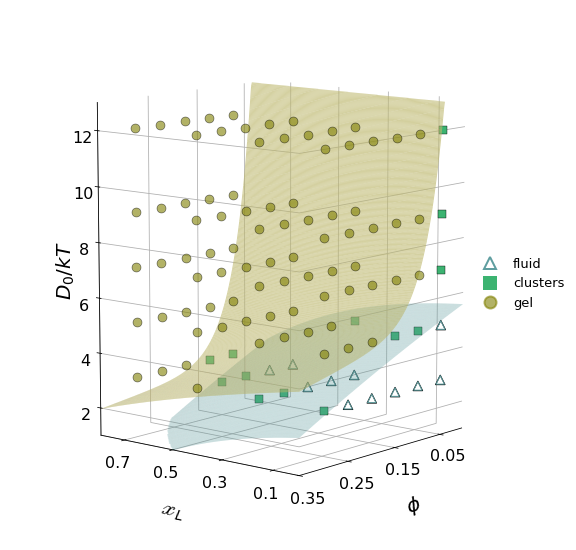

In [17]:
mpl.rcParams['figure.dpi'] = 70

fluids = phase_df.loc[(phase_df['phase'] == 'fluid') & (phase_df['phi_L'] != 1.0)]
clusters = phase_df.loc[(phase_df['phase'] == 'clusters') & (phase_df['phi_L'] != 1.0)]
gels = phase_df.loc[(phase_df['phase'] == 'gel') & (phase_df['phi_L'] != 1.0)]
present = set(phase_df["phase"].unique())

phi_wall   = 0.075   # plane sits just above the phi=0.05 column
x_wall     = 0.22    # wall spans only low x_L, where the column exists
D0_wall_lo = 6.0     # wall runs from here to the top of the box

clusters_hi = clusters[clusters['phi'] > 0.06]   # clusters NOT in the phi=0.05 column

def boundary_surface(lower, upper, GX, GY, deg=2, C_val=50, balanced=True,
                     phi_bump=False, bump_lambda=0.04, margin=0.0):
    """P=0.5 logistic boundary height D0(x,y).
       phi_bump adds an exp(-phi/lambda) basis so the sheet can spike at low phi
       (capping the phi=0.05 cluster column) without lifting the rest."""
    if len(lower) == 0 or len(upper) == 0:
        return None
    fc = pd.concat([lower.assign(_l=0), upper.assign(_l=1)], ignore_index=True)
    poly = PolynomialFeatures(degree=deg, include_bias=False)
    Pxy = poly.fit_transform(fc[['phi_L', 'phi']].values)

    bump = lambda phi: np.exp(-np.asarray(phi) / bump_lambda)   # large at low phi

    if phi_bump:
        feat = np.hstack([Pxy, bump(fc['phi'].values)[:, None], fc[['D0']].values])
    else:
        feat = np.hstack([Pxy, fc[['D0']].values])

    clf = LogisticRegression(C=C_val, max_iter=5000,
                             class_weight=('balanced' if balanced else None)
                             ).fit(feat, fc['_l'].values)
    w, b = clf.coef_[0], clf.intercept_[0]
    w_U = w[-1]
    if abs(w_U) < 1e-9:
        return None

    Pg = poly.transform(np.column_stack([GX.ravel(), GY.ravel()]))
    if phi_bump:
        w_poly, w_ex = w[:Pxy.shape[1]], w[Pxy.shape[1]:-1]
        lin = b + Pg @ w_poly + bump(GY.ravel()) * w_ex[0]
    else:
        lin = b + Pg @ w_poly if False else b + Pg @ w[:-1]
    return (-lin / w_U + margin).reshape(GX.shape)

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')

# --- shared grid for the volume ---
nx, ny, nz = 30, 24, 26           # voxel resolution (raise for smoother, slower)
x_edges = np.linspace(0.0, 0.8, nx + 1)
y_edges = np.linspace(0.0, 0.35, ny + 1)
z_edges = np.linspace(1.0, 13.0, nz + 1)
xc = 0.5 * (x_edges[:-1] + x_edges[1:])
yc = 0.5 * (y_edges[:-1] + y_edges[1:])
zc = 0.5 * (z_edges[:-1] + z_edges[1:])

GX, GY = np.meshgrid(xc, yc, indexing='ij')      # (nx, ny)
Z_fc = boundary_surface(fluids,   clusters, GX, GY, deg=3, C_val=300)   # fluid/cluster surface
Z_cg = boundary_surface(clusters, gels, GX, GY, deg=3, C_val=1000, phi_bump=True, margin=-0.3) # cluster/gel surface

# --- classify every voxel by its center's D0 vs the two surfaces ---
# broadcast surfaces to (nx, ny, nz)
ZC = zc[None, None, :]                            # (1,1,nz)
fc_s = Z_fc[:, :, None] if Z_fc is not None else np.full((nx, ny, 1), np.inf)
cg_s = Z_cg[:, :, None] if Z_cg is not None else np.full((nx, ny, 1),  np.inf)

is_fluid_v    = ZC <  fc_s
is_cluster_v  = (ZC >= fc_s) & (ZC <  cg_s)
is_gel_v      = ZC >= cg_s

##############
# --- build a colors array and a filled mask for voxels ---
is_fluid_v   = np.asarray(is_fluid_v,   dtype=bool)
is_cluster_v = np.asarray(is_cluster_v, dtype=bool)
is_gel_v     = np.asarray(is_gel_v,     dtype=bool)

# --- recolor the phi=0.05 cluster column back to green ---
x_col   = 0.08    # capture the x_L=0.05 data column (widen to include more)
phi_col = 0.075   # capture the phi=0.05 row (below this)
D0_col  = 6.0     # column rises from here to the top of the box

XCv = xc[:, None, None]
YCv = yc[None, :, None]
column = (XCv <= x_col) & (YCv < phi_col) & (ZC >= D0_col)

is_cluster_v = is_cluster_v | column
is_gel_v     = is_gel_v & ~column
is_fluid_v   = is_fluid_v & ~column     # safety; nothing at D0>=6 is fluid anyway
################

base_shape = is_gel_v.shape                         # (nx, ny, nz)
colors = np.zeros(base_shape + (4,), dtype=float)   # <-- trailing 4 axis, float

colors[is_fluid_v]   = to_rgba('darkturquoise',  0.02)    #0.06)
colors[is_cluster_v] = to_rgba('darkgreen', 0.05) #0.06)
colors[is_gel_v]     = to_rgba('darkkhaki',  0.03) # 0.06)

filled = np.ones(base_shape, dtype=bool)

# full 3-D corner grids, shape (nx+1, ny+1, nz+1)
XE, YE, ZE = np.meshgrid(x_edges, y_edges, z_edges, indexing='ij')

#### VOXEL COLOR
#ax.voxels(XE, YE, ZE, filled,
#          facecolors=colors, edgecolor=None, shade=False)
#######

# --- dividing surfaces between the three regions ---
# finer grid than the voxels, just for smooth membranes
sx = np.linspace(0.0, 0.8,  200)
sy = np.linspace(0.0, 0.35, 200)
SX, SY = np.meshgrid(sx, sy, indexing='ij')

S_fc = boundary_surface(fluids,   clusters, SX, SY, deg=3, C_val=300)   # same fit, finer sampling
S_cg = boundary_surface(clusters_hi, gels, SX, SY, deg=3, C_val=1000)   # fine grid
S_cg = boundary_surface(clusters, gels, SX, SY, deg=3, C_val=1000, phi_bump=True, margin=-0.3)

def clip_flat(Z, color, alpha, lo=1.0, hi=13.0, eps=1e-6):
    """Clamp Z into [lo,hi], then hide quads sitting entirely on the top lid
    or bottom floor. Straddling quads stay visible, so the surface is cut by a
    straight horizontal line at the box edge instead of a jagged NaN frontier."""
    if Z is None:
        return None, None
    Zc = np.clip(Z, lo, hi)
    top = Zc >= hi - eps
    bot = Zc <= lo + eps
    q_top = top[:-1,:-1] & top[1:,:-1] & top[:-1,1:] & top[1:,1:]
    q_bot = bot[:-1,:-1] & bot[1:,:-1] & bot[:-1,1:] & bot[1:,1:]
    fc = np.empty(Zc.shape + (4,)); fc[...] = to_rgba(color, alpha)
    fc[:-1,:-1][q_top | q_bot] = (0, 0, 0, 0)   # transparent on lid/floor
    return Zc, fc

phi_fc_max = fluids['phi'].max() + 0.2 #0.025      # keep sheet only where fluid data reaches
S_fc[SY > phi_fc_max] = np.nan                     # straight vertical cut at phi = const

S_fc_z, S_fc_c = clip_flat(S_fc, 'cadetblue', 0.35)   # then clip as before

S_cg_z, S_cg_c = clip_flat(S_cg, 'darkkhaki', 0.65)

if S_fc_z is not None:
    ax.plot_surface(SX, SY, S_fc_z, facecolors=S_fc_c,
                    linewidth=0, antialiased=True, shade=False,
                    rcount=200, ccount=200)
if S_cg_z is not None:
    ax.plot_surface(SX, SY, S_cg_z, facecolors=S_cg_c,
                    linewidth=0, antialiased=True, shade=False,
                    rcount=200, ccount=200)

# --- keep the points on top ---
# back layer: slightly larger, black edge -> becomes the thin outer ring
ax.scatter(fluids['phi_L'],   fluids['phi'],   fluids['D0'],  facecolor="none",    
           edgecolors='k', linewidths=1.1, s=88, marker='^', depthshade=False, zorder=1)
# front layer: your hollow colored marker on top
ax.scatter(fluids['phi_L'],   fluids['phi'],   fluids['D0'],   facecolor="none",    
           edgecolors='cadetblue', linewidths=1, s=72, marker='^', depthshade=False, zorder=1.1)

ax.scatter(clusters['phi_L'], clusters['phi'], clusters['D0'], color='mediumseagreen',
           edgecolors='k', linewidths=0.4, s=80, marker='s', depthshade=False)

ax.scatter(gels['phi_L'],     gels['phi'],     gels['D0'],     color='olive',     alpha=0.6,     
           edgecolors='k', linewidths=0.6, s=80,             depthshade=False)

ax.xaxis.set_pane_color((1, 1, 1, 0))
ax.yaxis.set_pane_color((1, 1, 1, 0))
ax.zaxis.set_pane_color((1, 1, 1, 0))
ax.view_init(elev=10, azim=130)

### COMPOSITION
ax.set_xticks(np.arange(0.1, 0.9, 0.2))
ax.set_xlabel(r'$\mathscr{x}_L$', fontsize=20, labelpad=20)
ax.set_xlim(0.0,0.8)

### TOTAL VOLUME FRACTION
ax.set_ylim(0.0,0.35)
ax.set_yticks(np.arange(0.05, 0.45, 0.1))
ax.set_ylabel(r'$\phi$', fontsize=20, labelpad=20)

# ATTRACTION
tmp = ax.zaxis._PLANES
ax.zaxis._PLANES = (tmp[2], tmp[3], tmp[0], tmp[1], tmp[4], tmp[5])
ax.zaxis.set_rotate_label(False)          # stop auto-rotation
ax.set_zlim(1,13)
ax.set_zticks(np.arange(2, 13, 2))
ax.set_zlabel(r'$D_0/kT$',
              rotation=90, fontsize=20)

ax.tick_params(axis='both', labelsize=16)

# ---- (1) widen margins so the z-axis label is visible ----
fig.subplots_adjust(left=0.0, right=0.98, bottom=0.05, top=0.98)
ax.set_box_aspect((1, 1, 1.3), zoom=0.90)

# legend:
PHASE_STYLE = {
    "fluid":      dict(color="cadetblue",        marker="^", open=True),
    "clusters":   dict(color="mediumseagreen",   marker="s", open=False),
    "gel":        dict(color="olive",            marker="o", open=False),
}
handles = []
for ph, st in PHASE_STYLE.items():
    if ph not in present: continue
    mfc = "none" if st.get("open") else st["color"]
    handles.append(Line2D([0],[0], marker=st["marker"], color="w",
                          markerfacecolor=mfc, markeredgecolor=st["color"], markeredgewidth=2,
                          markersize=12, alpha=(0.60 if ph=='gel' else 1.0), label=ph))
fig.legend(handles=handles, loc="center left", ncol=1,
           frameon=False, bbox_to_anchor=(0.82, 0.5), fontsize=13)

plt.show()

#### 2D projections

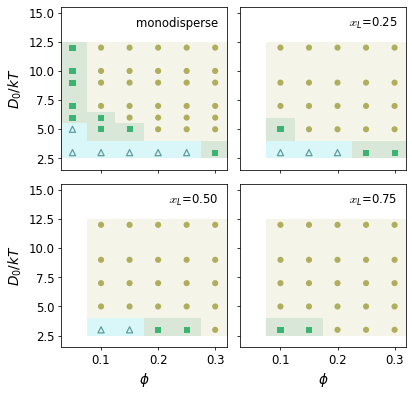

In [18]:
mpl.rcParams['figure.dpi'] = 70

# fill colors per phase (lighter than the markers)
PHASE_FILL = {
    "fluid":    to_rgba("darkturquoise",      0.15),
    "clusters": to_rgba("darkgreen", 0.15),
    "gel":      to_rgba("darkkhaki",   0.15),
}
PHASE_ORDER = ["fluid", "clusters", "gel"]   # low D0 -> high D0

def shade_phase_columns(ax, panel, x_col, d0_col, phase_col,
                        d0_lim, x_lim, half_gap=None):
    """Stepwise phase shading: one vertical band per phi_L column, split in
    D0 at the midpoints between adjacent samples where the phase changes."""
    xs = np.sort(panel[x_col].unique())
    # half-width of each column's shaded band in phi_L (midpoints to neighbors)
    if len(xs) > 1:
        mids = 0.5 * (xs[:-1] + xs[1:])
        left_edges  = np.concatenate([[xs[0] - (mids[0]-xs[0])], mids])
        right_edges = np.concatenate([mids, [xs[-1] + (xs[-1]-mids[-1])]])
    else:
        w = 0.5 * (x_lim[1]-x_lim[0]) * 0.15
        left_edges, right_edges = xs - w, xs + w

    for xv, xl, xr in zip(xs, left_edges, right_edges):
        col = panel[panel[x_col] == xv].sort_values(d0_col)
        d0s = col[d0_col].to_numpy()
        phs = col[phase_col].to_numpy()
        if len(d0s) == 0:
            continue
        # D0 band edges: midpoints between consecutive samples, plus axis ends
        b_lo = np.concatenate([[d0_lim[0]], 0.5*(d0s[:-1]+d0s[1:])])
        b_hi = np.concatenate([0.5*(d0s[:-1]+d0s[1:]), [d0_lim[1]]])
        for ph, lo, hi in zip(phs, b_lo, b_hi):
            ax.fill_between([xl, xr], lo, hi,
                            color=PHASE_FILL.get(ph, (0,0,0,0)),
                            linewidth=0, zorder=0)

# open=True -> hollow marker (facecolors 'none')
PHASE_STYLE = {
    "fluid":      dict(color="cadetblue",        marker="^", open=True),
    "clusters":   dict(color="mediumseagreen",   marker="s", open=False),
    "gel":        dict(color="olive",            marker="o", open=False),
}
BOUNDARY_COLOR = {
    ("fluid", "clusters"): "olive",
    ("clusters", "gel"):   "mediumpurple",
}

def _fit_boundary(df, lower, upper, x_col, phi_col, d0_col, degree, C):
    sub = df[df["_phase"].isin([lower, upper])].copy()
    if sub["_phase"].nunique() < 2:
        return None
    y = (sub["_phase"] == upper).astype(int).values
    poly = PolynomialFeatures(degree=degree, include_bias=False)
    Pxy = poly.fit_transform(sub[[x_col, phi_col]].values)   # (phi_L, phi)
    feat = np.hstack([Pxy, sub[[d0_col]].values])
    clf = LogisticRegression(C=C, max_iter=5000).fit(feat, y)
    w, b = clf.coef_[0], clf.intercept_[0]
    w_poly, w_d0 = w[:-1], w[-1]
    if abs(w_d0) < 1e-9:
        return None
    return dict(poly=poly, w_poly=w_poly, w_d0=w_d0, b=b,
                phi_range=(sub[phi_col].min(), sub[phi_col].max()))

def _boundary_D0_vs_phi(fit, phi_L_value, phi_grid):
    Pg = fit["poly"].transform(
        np.column_stack([np.full_like(phi_grid, phi_L_value), phi_grid]))
    return -(fit["b"] + Pg @ fit["w_poly"]) / fit["w_d0"]

def _scatter_phase(ax, x, y, st, gel):
    kw = dict(marker=st["marker"], s=40,#(15 if gel else 30),
              alpha=(0.60 if gel else 1.0), 
              zorder=(1 if gel else 3))
    if st.get("open", False):
        kw.update(facecolors="none", edgecolors=st["color"], linewidths=1.3)
    else:
        kw.update(facecolors=st["color"], edgecolors="none")
    ax.scatter(x, y, **kw)

phase_df
phi_col="phi"
x_col="phi_L"

phase_col="phase"
boundaries=(("fluid","clusters",1),("clusters","gel",2))
C=1.0
ncols=2
jitter_w=0.02
mono_vals=(0.0, 1.0)
d0_lim=None
phi_lim=None
phi_label=r"$\phi$"
d0_label=r"$D_0/kT$"
figsize=(6, 6)


df = phase_df.copy()
df["_phase"] = df[phase_col]
df['D0_plot'] = df['D0']
df.loc[df['phi_L'] == 1.0, 'D0_plot'] *= 2
# drop rescaled phi_L=1 rows that now exceed the axis
df = df[~((df['phi_L'] == 1.0) & (df['D0_plot'] >= 13))]

d0_col="D0_plot"
all_phiL = sorted(df[x_col].dropna().unique())
mono = [v for v in all_phiL if v in mono_vals]
bi   = [v for v in all_phiL if v not in mono_vals]

# build panels: one combined monodisperse panel + one per bimodal phi_L
panels = []
if mono:
    panels.append(dict(title="monodisperse", phiLs=mono))
for v in bi:
    panels.append(dict(title=r"$\mathscr{x}_L$ = "+f"{v:g}", phiLs=[v]))
    

n = len(panels); ncols = min(ncols, n); nrows = int(np.ceil(n/ncols))
if figsize is None: figsize = (3.8*ncols, 3.2*nrows)
fig, axes = plt.subplots(nrows, ncols, figsize=figsize,
                         squeeze=False, sharex=True, sharey=True)

panel_labels = ['monodisperse','$\mathscr{x}_L$=0.25','$\mathscr{x}_L$=0.50','$\mathscr{x}_L$=0.75']

fits = {}
for lo, up, deg in boundaries:
    fits[(lo, up)] = _fit_boundary(df, lo, up, x_col, phi_col, d0_col, deg, C)

if d0_lim is None: d0_lim = (df[d0_col].min()-0.5, df[d0_col].max()+0.5)
if phi_lim is None:
    pad = max(0.02*((df[phi_col].max()-df[phi_col].min()) or 1), jitter_w)
    phi_lim = (df[phi_col].min()-pad, df[phi_col].max()+pad)
phig = np.linspace(phi_lim[0], phi_lim[1], 200)
linestyles = ["-", "--", ":", "-."]

present = set(df["_phase"].unique())

for i, p in enumerate(panels):
    ax = axes[i//ncols][i%ncols]
    pls = p["phiLs"]
    offs = [0.0] * len(pls) # no jitter: both datasets on the same x

    # phase regions
    panel_df = df[df[x_col].isin(pls)]
    shade_phase_columns(ax, panel_df, phi_col, d0_col, "_phase", d0_lim, phi_lim)
    
    for off, pl in zip(offs, pls):
        sub = df[df[x_col] == pl]
        
        for ph, st in PHASE_STYLE.items():
            pts = sub[sub["_phase"] == ph]
            if len(pts) == 0: continue
            _scatter_phase(ax, pts[phi_col] + off, pts[d0_col], st, ph == "gel")

    text_label = panel_labels[i]
    ax.text(0.95, 0.9, text_label, horizontalalignment='right',
        verticalalignment='center', fontsize=12, transform=ax.transAxes)

    ax.set_xlim(phi_lim); ax.set_ylim(d0_lim)

for j in range(n, nrows*ncols):
    axes[j//ncols][j%ncols].axis("off")
for ax in axes[-1]: ax.set_xlabel(phi_label, fontsize=14)
for ax in axes[-1]: ax.set_ylim(1.5,15.5)
for ax in axes[0]: ax.tick_params(axis='both', labelsize=12)
for ax in axes[-1]: ax.tick_params(axis='both', labelsize=12)
for r in range(nrows): axes[r][0].set_ylabel(d0_label, fontsize=14)
            
# legend: only phases actually present
#handles = []
#for ph, st in PHASE_STYLE.items():
#    if ph not in present: continue
#    mfc = "none" if st.get("open") else st["color"]
#    handles.append(Line2D([0],[0], marker=st["marker"], color="w",
#                          markerfacecolor=mfc, markeredgecolor=st["color"],
#                          markersize=8, alpha=(0.60 if ph=='gel' else 1.0), label=ph))
#for (lo, up), col in BOUNDARY_COLOR.items():
#    if fits.get((lo, up)) is not None:
#        handles.append(Line2D([0],[0], color=col, lw=2, label=f"{lo}\u2194{up}"))
#fig.legend(handles=handles, loc="upper center", ncol=len(handles),
#           frameon=False, bbox_to_anchor=(0.5, 1.03), fontsize=9)

fig.tight_layout(rect=[0,0,1,0.96])

plt.show()

### 2D phase diagram

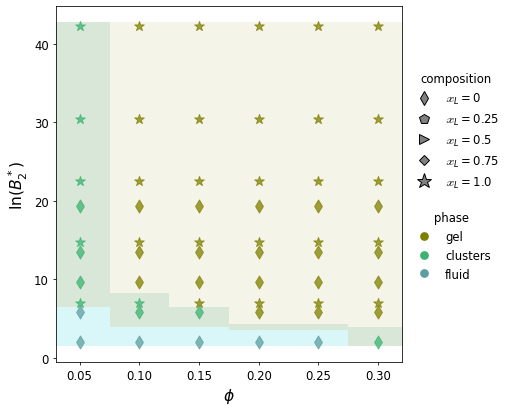

In [19]:
mpl.rcParams['figure.dpi'] = 70 #300

# fill colors per phase (lighter than the markers)
PHASE_FILL = {
    "fluid":    to_rgba("darkturquoise",      0.15),
    "clusters": to_rgba("darkgreen", 0.15),
    "gel":      to_rgba("darkkhaki",   0.15),
}
PHASE_ORDER = ["fluid", "clusters", "gel"]   # low D0 -> high D0

def shade_phase_columns(ax, panel, x_col, d0_col, phase_col,
                        d0_lim, x_lim, half_gap=None):
    """Stepwise phase shading: one vertical band per phi_L column, split in
    D0 at the midpoints between adjacent samples where the phase changes."""
    xs = np.sort(panel[x_col].unique())
    # half-width of each column's shaded band in phi_L (midpoints to neighbors)
    if len(xs) > 1:
        mids = 0.5 * (xs[:-1] + xs[1:])
        left_edges  = np.concatenate([[xs[0] - (mids[0]-xs[0])], mids])
        right_edges = np.concatenate([mids, [xs[-1] + (xs[-1]-mids[-1])]])
    else:
        w = 0.5 * (x_lim[1]-x_lim[0]) * 0.15
        left_edges, right_edges = xs - w, xs + w

    for xv, xl, xr in zip(xs, left_edges, right_edges):
        col = panel[panel[x_col] == xv].sort_values(d0_col)
        d0s = col[d0_col].to_numpy()
        phs = col[phase_col].to_numpy()
        if len(d0s) == 0:
            continue
        # D0 band edges: midpoints between consecutive samples, plus axis ends
        b_lo = np.concatenate([[d0_lim[0]], 0.5*(d0s[:-1]+d0s[1:])])
        b_hi = np.concatenate([0.5*(d0s[:-1]+d0s[1:]), [d0_lim[1]]])
        for ph, lo, hi in zip(phs, b_lo, b_hi):
            ax.fill_between([xl, xr], lo, hi,
                            color=PHASE_FILL.get(ph, (0,0,0,0)),
                            linewidth=0, zorder=0)


# marker/color per phase (matches the 3D: green^ suspension, red[] clusters, blue o gel)
PHASE_STYLE = {
    "fluid":      dict(color="cadetblue",        marker="^", open=True),
    "clusters":   dict(color="mediumseagreen",   marker="s", open=False),
    "gel":        dict(color="olive",            marker="o", open=False),
}

pcol = {"fluid": "cadetblue", "clusters": "mediumseagreen", "gel": "olive"}
mark_dict = {}
for m, mark in enumerate(comp_mark_dataset):
    phi_L = phi_L_vals[m]
    mark_dict[phi_L] = mark

fig, ax = plt.subplots(figsize=(7.4, 6.0))
bi_df = phase_df.loc[(phase_df['phi_L'] != 0.0) & (phase_df['phi_L'] != 1.0)]
mono_df = phase_df.loc[(phase_df['phi_L'] == 0.0) | (phase_df['phi_L'] == 1.0)]

bi_phi_Ls = sorted(pd.unique(bi_df['phi_L']))
m_phi_Ls = sorted(pd.unique(mono_df['phi_L']))

if d0_lim is None:
    d0_lim = (df[d0_col].min() - 0.5, df[d0_col].max() + 0.5)

pad = 0.02 * (df[x_col].max() - df[x_col].min() or 1)
x_lim = (df[x_col].min() - pad, df[x_col].max() + pad)
xg = np.linspace(x_lim[0], x_lim[1], 200)

clean = mono_df[mono_df['phase'].isin(['fluid', 'clusters', 'gel'])]

ylim = (phase_df['lnB2_ct'].min() - 0.5, phase_df['lnB2_ct'].max() + 0.5)
xlim = (0.03, 0.32)

shade_phase_columns(ax, clean, "phi", "lnB2_ct", "phase", ylim, xlim)

# --- manual thin cluster region in the fluid->gel gap ---
# find the gap from the mono data in that phi range
region = clean[(clean['phi'] >= 0.2) & (clean['phi'] <= 0.25)]
fluid_max = region.loc[region['phase'] == 'fluid', 'lnB2_ct'].max()   # top of fluid
gel_min = region.loc[region['phase'] == 'gel',   'lnB2_ct'].min()   # bottom of gel
x_lo, x_hi = 0.175, 0.275    # horizontal span of the inserted band
y_lo = ((fluid_max+gel_min)/2)-0.3
y_hi = y_lo + 0.75
ax.fill_between([x_lo, x_hi], y_lo, y_hi,
                color='white', linewidth=0, zorder=0)
ax.fill_between([x_lo, x_hi], y_lo, y_hi,
                color=PHASE_FILL['clusters'], linewidth=0, zorder=0)

for phi_L in m_phi_Ls:
    sub = mono_df.loc[mono_df['phi_L'] == phi_L]
    for phase in pd.unique(sub['phase']):
        pts = sub.loc[sub['phase'] == phase]
        marker = mark_dict[phi_L]
        s=90
        if marker == '*':
            s = 110
        ax.scatter(pts['phi'], pts['lnB2_ct'],
                   s=s, c=pcol[phase], marker=marker,
                   #edgecolor="white", linewidth=0.6, 
                   zorder=4, alpha=0.75)

ax.set_xlabel('$\phi$', fontsize=16)
ax.set_ylabel('$\\text{ln}(B_2^*)$', fontsize=16)
ax.tick_params(axis='both', labelsize=12)

PHASE_ORDER = ["gel", "clusters", "fluid"]
marker_size_dict = {0.0: 10, 0.25: 11, 0.5: 10, 0.75: 8, 1.0: 16}
phase_leg = [Line2D([0], [0], marker='o', color='w', markerfacecolor=pcol[p],
             markeredgecolor='none', markersize=9, label=p) for p in PHASE_ORDER]
comp_leg = [Line2D([0], [0], marker=mark_dict[p], color='w', markerfacecolor='gray',
            markeredgecolor='black', markersize=marker_size_dict[p], label=r"$\mathscr{x}_L=$"+f"{p}") for p in phi_L_vals]

leg1 = ax.legend(handles=phase_leg, title="phase", frameon=False, loc="lower left", bbox_to_anchor=(1,0.2), title_fontsize=12, fontsize=12)
ax.add_artist(leg1)
ax.legend(handles=comp_leg, title="composition", frameon=False, loc="center left", bbox_to_anchor=(1,0.65), title_fontsize=12, fontsize=12)
ax.set_xlim(0.03,0.32)

plt.tight_layout()
plt.show()

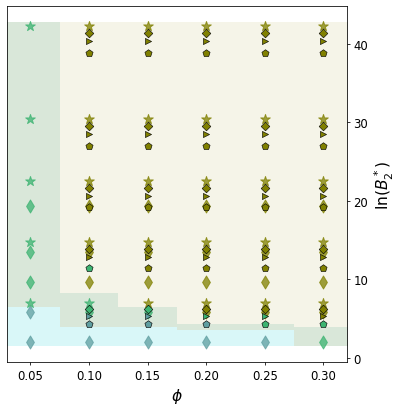

In [20]:
mpl.rcParams['figure.dpi'] = 70

# fill colors per phase (lighter than the markers)
PHASE_FILL = {
    "fluid":    to_rgba("darkturquoise",      0.15),
    "clusters": to_rgba("darkgreen", 0.15),
    "gel":      to_rgba("darkkhaki",   0.15),
}
PHASE_ORDER = ["fluid", "clusters", "gel"]   # low D0 -> high D0

def shade_phase_columns(ax, panel, x_col, d0_col, phase_col,
                        d0_lim, x_lim, half_gap=None):
    """Stepwise phase shading: one vertical band per phi_L column, split in
    D0 at the midpoints between adjacent samples where the phase changes."""
    xs = np.sort(panel[x_col].unique())
    # half-width of each column's shaded band in phi_L (midpoints to neighbors)
    if len(xs) > 1:
        mids = 0.5 * (xs[:-1] + xs[1:])
        left_edges  = np.concatenate([[xs[0] - (mids[0]-xs[0])], mids])
        right_edges = np.concatenate([mids, [xs[-1] + (xs[-1]-mids[-1])]])
    else:
        w = 0.5 * (x_lim[1]-x_lim[0]) * 0.15
        left_edges, right_edges = xs - w, xs + w

    for xv, xl, xr in zip(xs, left_edges, right_edges):
        col = panel[panel[x_col] == xv].sort_values(d0_col)
        d0s = col[d0_col].to_numpy()
        phs = col[phase_col].to_numpy()
        if len(d0s) == 0:
            continue
        # D0 band edges: midpoints between consecutive samples, plus axis ends
        b_lo = np.concatenate([[d0_lim[0]], 0.5*(d0s[:-1]+d0s[1:])])
        b_hi = np.concatenate([0.5*(d0s[:-1]+d0s[1:]), [d0_lim[1]]])
        for ph, lo, hi in zip(phs, b_lo, b_hi):
            ax.fill_between([xl, xr], lo, hi,
                            color=PHASE_FILL.get(ph, (0,0,0,0)),
                            linewidth=0, zorder=0)


# marker/color per phase (matches the 3D: green^ suspension, red[] clusters, blue o gel)
PHASE_STYLE = {
    "fluid":      dict(color="cadetblue",        marker="^", open=True),
    "clusters":   dict(color="mediumseagreen",   marker="s", open=False),
    "gel":        dict(color="olive",            marker="o", open=False),
}

pcol = {"fluid": "cadetblue", "clusters": "mediumseagreen", "gel": "olive"}
mark_dict = {}
for m, mark in enumerate(comp_mark_dataset):
    phi_L = phi_L_vals[m]
    mark_dict[phi_L] = mark

fig, ax = plt.subplots(figsize=(5.85, 6.0))
bi_df = phase_df.loc[(phase_df['phi_L'] != 0.0) & (phase_df['phi_L'] != 1.0)]
mono_df = phase_df.loc[(phase_df['phi_L'] == 0.0) | (phase_df['phi_L'] == 1.0)]

bi_phi_Ls = sorted(pd.unique(bi_df['phi_L']))
m_phi_Ls = sorted(pd.unique(mono_df['phi_L']))

if d0_lim is None:
    d0_lim = (df[d0_col].min() - 0.5, df[d0_col].max() + 0.5)

pad = 0.02 * (df[x_col].max() - df[x_col].min() or 1)
x_lim = (df[x_col].min() - pad, df[x_col].max() + pad)
xg = np.linspace(x_lim[0], x_lim[1], 200)

# monodisperse only, real phases only (drops 'other'/outlier from the SHADING)
clean = mono_df[mono_df['phase'].isin(['fluid', 'clusters', 'gel'])]

ylim = (phase_df['lnB2_ct'].min() - 0.5, phase_df['lnB2_ct'].max() + 0.5)
xlim = (0.03, 0.32)

shade_phase_columns(ax, clean, "phi", "lnB2_ct", "phase", ylim, xlim)

# --- manual thin cluster region in the fluid->gel gap ---
# find the gap from the mono data in that phi range
region = clean[(clean['phi'] >= 0.2) & (clean['phi'] <= 0.25)]
fluid_max = region.loc[region['phase'] == 'fluid', 'lnB2_ct'].max()   # top of fluid
gel_min = region.loc[region['phase'] == 'gel',   'lnB2_ct'].min()   # bottom of gel
x_lo, x_hi = 0.175, 0.275    # horizontal span of the inserted band
y_lo = ((fluid_max+gel_min)/2)-0.3
y_hi = y_lo + 0.75
ax.fill_between([x_lo, x_hi], y_lo, y_hi,
                color='white', linewidth=0, zorder=0)
ax.fill_between([x_lo, x_hi], y_lo, y_hi,
                color=PHASE_FILL['clusters'], linewidth=0, zorder=0)

for phi_L in m_phi_Ls:
    sub = mono_df.loc[mono_df['phi_L'] == phi_L]
    for phase in pd.unique(sub['phase']):
        pts = sub.loc[sub['phase'] == phase]
        marker = mark_dict[phi_L]
        s=90
        if marker == '*':
            s = 110
        ax.scatter(pts['phi'], pts['lnB2_ct'],
                   s=s, c=pcol[phase], marker=marker,
                   alpha=0.75)

#for phi_L, off in zip(bi_phi_Ls, offsets):
for phi_L in bi_phi_Ls:
    sub = bi_df.loc[bi_df['phi_L'] == phi_L]          # <-- restrict to this phi_L
    for phase in pd.unique(sub['phase']):             # <-- unique phases only
        pts = sub.loc[sub['phase'] == phase]
        marker = mark_dict[phi_L]
        s=40
        if marker == 'p':
            s = 60
        ax.scatter(pts['phi'], pts['lnB2_ct'],
                   s=s, c=pcol[phase], marker=marker,
                   edgecolor="black", linewidth=0.6, 
                   #zorder=3, 
                   alpha=1.0) #0.6)


ax.set_xlabel('$\phi$', fontsize=16)
ax.set_ylabel('$\\text{ln}(B_2^*)$', fontsize=16)
ax.tick_params(axis='both', labelsize=12)

ax.yaxis.tick_right()                 # moves the tick numbers to the right
ax.yaxis.set_label_position("right")  # moves the axis label to the right

PHASE_ORDER = ["gel", "clusters", "fluid"]
marker_size_dict = {0.0: 10, 0.25: 11, 0.5: 10, 0.75: 8, 1.0: 16}
phase_leg = [Line2D([0], [0], marker='o', color='w', markerfacecolor=pcol[p],
             markeredgecolor='none', markersize=9, label=p) for p in PHASE_ORDER]
comp_leg = [Line2D([0], [0], marker=mark_dict[p], color='w', markerfacecolor='gray',
            markeredgecolor='black', markersize=marker_size_dict[p], label=r"$\mathscr{x}_L=$"+f"{p}") for p in phi_L_vals]
#leg1 = ax.legend(handles=phase_leg, title="phase", frameon=False, loc="lower left", bbox_to_anchor=(1,0.2), title_fontsize=12, fontsize=12)
#ax.add_artist(leg1)
#ax.legend(handles=comp_leg, title="composition", frameon=False, loc="center left", bbox_to_anchor=(1,0.65), title_fontsize=12, fontsize=12)
ax.set_xlim(0.03,0.32)

plt.tight_layout()
plt.show()

In [21]:
#### YES IT IS A REAL OUTLIER

bi_phi10 = other_new_df.loc[(other_new_df['phase'] == 'clusters') & (other_new_df['phi'] == 0.1) & (other_new_df['phi_L'] == 0.25)]
mono_phi10 = other_new_df.loc[(other_new_df['phi_L'] == 0.0) & (other_new_df['phi'] == 0.10) & (other_new_df['D0'] == 7)]
real_outlier = pd.concat([bi_phi10,mono_phi10], ignore_index=True)
real_outlier

#square_phi10['avg_degree']
mono_phi10[['lnB2_ct','f_lcc','percolation','msd_diffusive','msd_caged','avg_degree']]
bi_phi10[['lnB2_ct','f_lcc','percolation','msd_diffusive','msd_caged','avg_degree']]
real_outlier_v2 = pd.concat([mono_phi10,bi_phi10], ignore_index=True)
real_outlier_v2[['lnB2_ct','f_lcc','percolation','msd_diffusive','msd_caged','avg_degree']]

,lnB2_ct,f_lcc,percolation,msd_diffusive,msd_caged,avg_degree
0,9.604609,0.998779,0.984821,False,True,6.441812
1,11.420375,0.082382,0.434412,True,False,3.287791


### Dynamics Data : phi=10

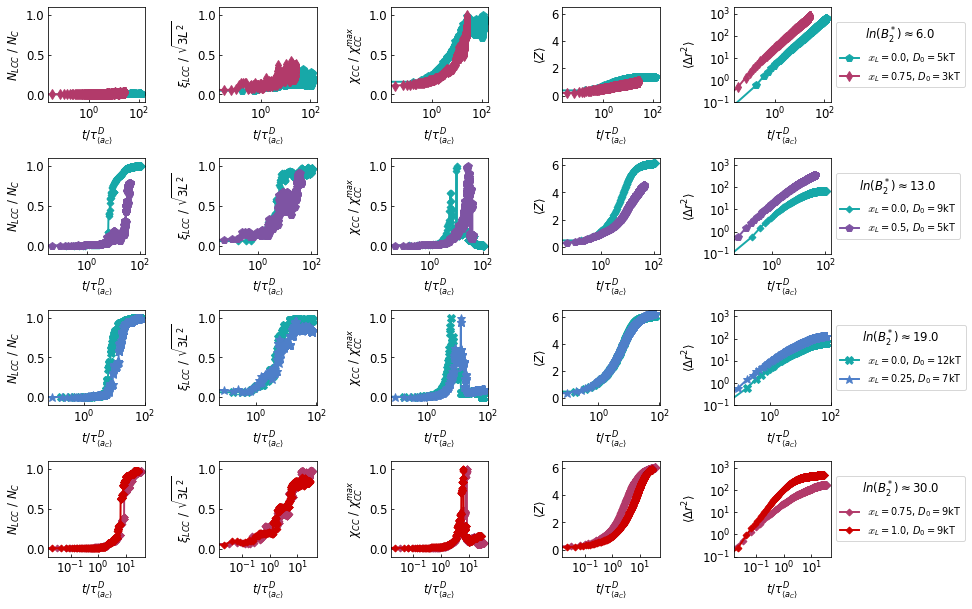

phi = 10% plot saved to phase-diagram-dynamics/dynamics_lnB2-phi10.png


In [22]:
a = np.sort(np.round(lnB2_ct_vals))
u, c = np.unique(a, return_counts=True)
multi_B2 = u[c > 1]
fontsize = 12
legendsize = 10

#plot_phi_vals = [0.10, 0.15, 0.20, 0.25, 0.30]
#plot_phi_labels = ['10', '15', '20', '25', '30']
plot_phi_vals = [0.10]
plot_phi_labels = ['10']

marker_size_list = [8, 8, 9, 5, 9]
df_plot = df_all.loc[df_all['network-type'] == 'allc']

for p, phi in enumerate(plot_phi_vals):
    phi_label = plot_phi_labels[p]
    phi = plot_phi_vals[p]
    
    fig, ax = plt.subplots(len(multi_B2), 5, figsize=(14, len(multi_B2)*2.2))
    
    for b, lnB2_bucket in enumerate(multi_B2):
        df_B2 = df_plot.loc[(np.round(df_plot['lnB2_ct']) == lnB2_bucket) &
                           (df_plot['phi'] == phi)]
        title = f"$ln(B_2^*)\\approx${lnB2_bucket}"
        alpha = 1

        for c, comp in enumerate(compositions):
            color = comp_color_list[c]
            phi_L = phi_L_vals[c]

            df_comp = df_B2.loc[df_B2['comp']== comp]

            for d, D0 in enumerate(D0_vals):
                df_D0 = df_comp.loc[df_comp['D0'] == D0]
            
                for e, lnB2_exact in enumerate(np.sort(df_D0['lnB2_ct'].unique())):
                    df = df_D0.loc[df_D0['lnB2_ct'] == lnB2_exact]
                    if df.empty:
                        continue

                    tauD = df['tauD_mean']
                    connectivity = df['f_lcc']
                    percolation = df['percolation']
                    cluster_size = df['chi_meanclustersize']/max(df['chi_meanclustersize'])
                    Zavg = df['Zavg_Z_any']
                    msd = df['msd_colloid']
            
                    mark = D0_mark_list[d]
                    m_size = marker_size_list[d]

                    label = r"$\mathscr{x}_L=$"+f"{float(phi_L)}, $D_0=${int(D0)}kT"
                    ax[b,0].plot(tauD, connectivity, color=color, marker=mark, markersize=m_size, 
                                 linestyle='-', alpha=alpha, lw=2, label=label)
                    ax[b,1].plot(tauD, percolation, color=color, marker=mark,  markersize=m_size,
                                 linestyle='-', alpha=alpha, lw=2, label=label)
                    ax[b,2].plot(tauD, cluster_size, color=color, marker=mark, markersize=m_size,
                                 linestyle='-', alpha=alpha, lw=2, label=label)
                    ax[b,3].plot(tauD, Zavg, color=color, marker=mark, markersize=m_size,
                                 linestyle='-', alpha=alpha, lw=2, label=label)
                    ax[b,4].plot(tauD, msd, color=color, marker=mark, markersize=m_size,
                                 linestyle='-', alpha=alpha, lw=2, label=label)

                    ax[b,0].set_xlabel(r'$t / \tau^D_{\langle a_C \rangle}$', fontsize=fontsize)
                    ax[b,0].set_ylabel(r'$N_{LCC}$ / $N_C$', fontsize=fontsize)
                    ax[b,0].set_xscale('log')
                    ax[b,0].set_yscale('linear')
                    ax[b,0].set_ylim(-0.1,1.1)
                    ax[b,0].tick_params(axis='both', which='both', direction='in', labelsize=fontsize)
                    ax[b,0].minorticks_off()

                    ax[b,1].set_xlabel(r'$t / \tau^D_{\langle a_C \rangle}$', fontsize=fontsize)
                    ax[b,1].set_ylabel(r'$\xi_{LCC}$ / $\sqrt{3L^2}$', fontsize=fontsize)
                    ax[b,1].set_xscale('log')
                    ax[b,1].set_yscale('linear')
                    ax[b,1].set_ylim(-0.1,1.1)
                    ax[b,1].tick_params(axis='both', which='both', direction='in', labelsize=fontsize)
                    ax[b,1].minorticks_off()
                    #ax[p,1].legend(title=title, title_fontsize=12, fontsize=fontsize)

                    ax[b,2].set_xlabel(r'$t / \tau^D_{\langle a_C \rangle}$', fontsize=fontsize)
                    ax[b,2].set_ylabel(r'$\chi_{CC}$ / $\chi_{CC}^{max}$', fontsize=fontsize)
                    ax[b,2].set_xscale('log')
                    ax[b,2].set_yscale('linear')
                    ax[b,2].set_ylim(-0.1,1.1)
                    ax[b,2].tick_params(axis='both', which='both', direction='in', labelsize=fontsize)
                    ax[b,2].minorticks_off()

                    ax[b,3].set_xlabel(r'$t / \tau^D_{\langle a_C \rangle}$', fontsize=fontsize)
                    ax[b,3].set_ylabel(r'$\langle Z \rangle$', fontsize=fontsize)
                    ax[b,3].set_xscale('log')
                    ax[b,3].set_yscale('linear')
                    ax[b,3].set_ylim(-0.5,6.5)
                    ax[b,3].tick_params(axis='both', which='both', direction='in', labelsize=fontsize)
                    ax[b,3].minorticks_off()

                    ax[b,4].set_xlabel(r'$t / \tau^D_{\langle a_C \rangle}$', fontsize=fontsize)
                    #ax[b,4].set_ylabel(r'Components (% colloids)', fontsize=fontsize)
                    ax[b,4].set_ylabel(r'$\langle \Delta r^2 \rangle$', fontsize=fontsize)
                    #ax[b,4].set_ylabel(r'Components', fontsize=fontsize)
                    ax[b,4].set_xscale('log')
                    ax[b,4].set_yscale('log')
                    ax[b,4].set_ylim(0.1,2e3)
                    ax[b,4].tick_params(axis='both', which='both', direction='in', labelsize=fontsize)
                    ax[b,4].minorticks_off()

                    ax[b,4].legend(prop={"size":legendsize}, title=title, 
                                   title_fontsize=fontsize, loc='center left', bbox_to_anchor=(1,0.5))
                    #alpha-=0.8
        
    
    plt.tight_layout()
    
    #lgd = plt.legend(prop={"size":12}, title=title, title_fontsize=12, loc='center left', bbox_to_anchor=(1,0.5))
    filename = f"{out_path}/dynamics_lnB2-phi{phi_label}.png"
    #plt.savefig(filename, dpi=300)
    plt.show()
    print(f"phi = {phi_label}% plot saved to {filename}")

#print("All figs saved")

### Decompose MSD and Zavg by population

phi=0.1, phi_L=0.0, D0=[9]kT, 110.52426603603845
phi=0.1, phi_L=0.5, D0=[5]kT, 42.38892146875501
phi=0.1, phi_L=0.75, D0=[9]kT, 35.04192799504355
phi=0.1, phi_L=1.0, D0=[9]kT, 27.896324747496106


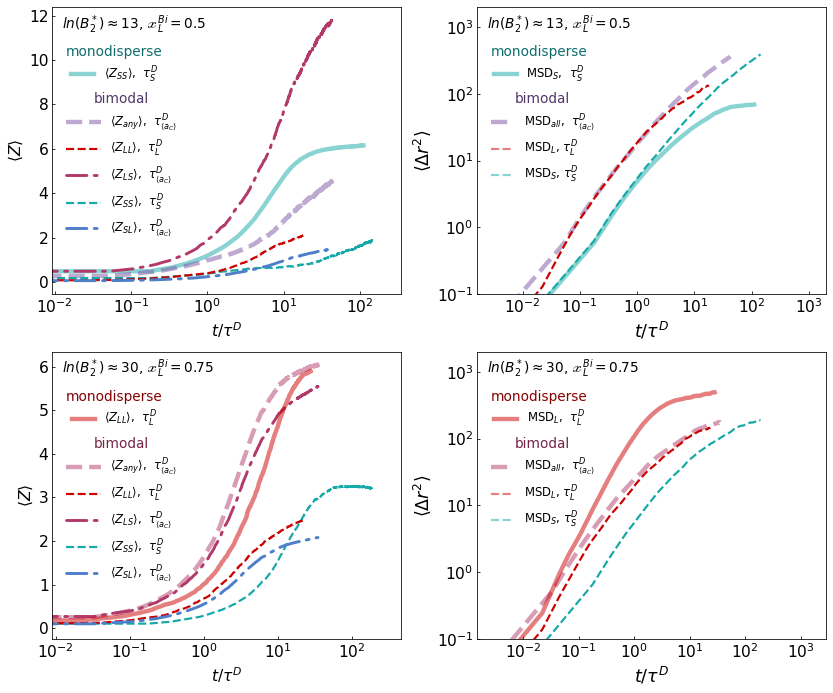

In [23]:
# each pop each normalized by its own bare diffusion time

def darken(color, factor=0.65):
    """Blend a color toward black. factor<1 = darker (0.65 → 65% of original brightness)."""
    r, g, b = mcolors.to_rgb(color)
    return (r * factor, g * factor, b * factor)

# pick a matched set: one phi, a narrow B2 window, all available comps
a = np.sort(np.round(lnB2_ct_vals))
u, c = np.unique(a, return_counts=True)
multi_B2 = u[c > 1]

plot_phi_vals = [0.10]
plot_phi_labels = ['10']

marker_size_list = [8, 8, 9, 5, 9]

color_SS = '#17A8A8'
color_SL = '#4E7FC9'
color_LS = '#B23A6A'
color_LL = '#CD0000'
color_mix = '#7E54A3'

lw_scale = 1.5
def dashdot_for_lw(lw, base=1.0):
    s = lw / base                      # scale factor relative to a reference lw
    on_dash = 7
    off     = 5 / s
    dot     = 1
    return (0, (on_dash, off, dot, off))

lw_Z = 2
dashdot = dashdot_for_lw(lw_Z)

def phiL_color(phi_L):
    return comp_color_list[phi_L_vals.index(phi_L)]

df_plot = df_all.loc[df_all['network-type'] == 'allc']

plot_multi_B2 = [13, 30]

for p, phi in enumerate(plot_phi_vals):
    phi_label = plot_phi_labels[p]
    phi = plot_phi_vals[p]
    
    fig, ax = plt.subplots(len(plot_multi_B2), 2, figsize=(12, len(plot_multi_B2)*5))

    for b, lnB2_bucket in enumerate(plot_multi_B2):    
        title = f"$ln(B_2^*)\\approx${lnB2_bucket}"
        phi_lab = f"$\phi={phi}$"
        
        sub = df_plot.loc[(df_plot['phi']==phi) & (np.round(df_plot['lnB2_ct']) == lnB2_bucket)]
        for (phi_L), g in sub.groupby('phi_L'):
            #print(phi_L)
            g = g.sort_values('tauD_mean')
            D0 = pd.unique(g['D0'])
            print(f"phi={phi}, phi_L={phi_L}, D0={D0}kT, {max(g['tauD_mean'])}")
            if (phi_L == 0.0): 
                m_c = phi_L_vals.index(phi_L) if phi_L in phi_L_vals else None
                m_color = comp_color_list[m_c]
                ax[b,1].plot(g['tauD_RS'], g['msd_colloid_1'], '-',  color=m_color, lw=3*lw_scale,
                          alpha=0.5, label=r'$\langle \Delta r_{S}^2 \rangle$, $\tau^D_{S}$')
                ax[b,0].plot(g['tauD_RS'], g['Zavg_Z_11'], '-',  color=m_color, lw=3*lw_scale,
                          alpha=0.5, label=r'$Z_{SS}$, $\tau^D_{S}$')
            elif (phi_L == 1.0):
                m_c = phi_L_vals.index(phi_L) if phi_L in phi_L_vals else None
                m_color = comp_color_list[m_c]
                ax[b,1].plot(g['tauD_RL'], g['msd_colloid_1'], '-', color=m_color, lw=3*lw_scale,
                          alpha=0.5, label=r'$\langle \Delta r_{L}^2 \rangle$, $\tau^D_{L}$')
                ax[b,0].plot(g['tauD_RL'], g['Zavg_Z_11'], '-', color=m_color, lw=3*lw_scale, 
                          alpha=0.5, label=r'$Z_{LL}$, $\tau^D_{L}$')
            else:
                b_c = phi_L_vals.index(phi_L) if phi_L in phi_L_vals else None
                b_color = comp_color_list[b_c]
                
                ax[b,1].plot(g['tauD_mean'], g['msd_colloid'], '--',  color=b_color, lw=3*lw_scale,
                          alpha=0.5, label=r'$\langle \Delta r_{all}^2 \rangle$, $\tau^D_{\langle a_C \rangle}$')
                ax[b,1].plot(g['tauD_RS'], g['msd_colloid_1'], '--',  color=color_SS, lw=1.5*lw_scale,
                          alpha=1.0, label=r'$\langle \Delta r_{S}^2 \rangle$, $\tau^D_{S}$')
                ax[b,1].plot(g['tauD_RL'], g['msd_colloid_2'], '--', color=color_LL, lw=1.5*lw_scale,
                          alpha=1.0, label=r'$\langle \Delta r_{L}^2 \rangle$, $\tau^D_{L}$')
                
                ax[b,0].plot(g['tauD_mean'], g['Zavg_Z_any'], '--',  color=b_color, lw=3*lw_scale,
                         alpha=0.5, label=r'$Z_{any}$, $\tau^D_{\langle a_C \rangle}$')
                ax[b,0].plot(g['tauD_RS'], g['Zavg_Z_11'], '--',  color=color_SS, lw=1.5*lw_scale,
                          alpha=1.0, label=r'$Z_{SS}$, $\tau^D_{S}$')
                ax[b,0].plot(g['tauD_RL'], g['Zavg_Z_22'], '--',  color=color_LL, lw=1.5*lw_scale,
                          alpha=1.0, label=r'$Z_{LL}$, $\tau^D_{L}$')

                ax[b,0].plot(g['tauD_mean'], g['Zavg_Z_12'], color=color_SL,    lw=2*lw_scale,
                             linestyle=dashdot, dash_capstyle='round',
                             label=r'$Z_{SL}$, $\tau^D_{\langle a_C \rangle}$')
                ax[b,0].plot(g['tauD_mean'], g['Zavg_Z_21'], color=color_LS, lw=2*lw_scale,
                             linestyle=dashdot, dash_capstyle='round',
                             label=r'$Z_{LS}$, $\tau^D_{\langle a_C \rangle}$')  

        row_phi_L = set(sub['phi_L'].unique())


        
        bimodal_phi_L = [k for k in row_phi_L if k not in (0.0, 1.0)]
        present_mono = [k for k in (0.0, 1.0) if k in row_phi_L]
        mono_title_color = phiL_color(present_mono[0]) if len(present_mono) == 1 else 'black'
        
        ax[b,1].set_xlabel(r'$t / \tau^D$', fontsize=18)
        ax[b,1].set_ylabel(r'$\langle \Delta r^2 \rangle$', fontsize=18)
    
        mono_entries_MSD = {
            0.0: Line2D([0], [0], color=phiL_color(0.0),    ls='-', lw=3*lw_scale, alpha=0.5,
                    label=r'$\text{MSD}_{S}$,  $\tau^D_{S}$'),   # SS
            1.0: Line2D([0], [0], color=phiL_color(1.0), ls='-', lw=3*lw_scale, alpha=0.5,
                    label=r'$\text{MSD}_{L}$,  $\tau^D_{L}$'),   # LL
        }
        
        bi_lgd_MSD = [
            Line2D([0], [0], color=phiL_color(bimodal_phi_L[0]),    ls='--', lw=3*lw_scale, alpha=0.5,
                   label=r'$\text{MSD}_{all}$,  $\tau^D_{\langle a_C\rangle}$'),
            Line2D([0], [0], color=color_LL, ls='--', lw=1.5*lw_scale, alpha=0.5,
                   label=r'$\text{MSD}_{L}$, $\tau^D_{L}$'),
            Line2D([0], [0], color=color_SS,    ls='--', lw=1.5*lw_scale, alpha=0.5,
                   label=r'$\text{MSD}_{S}$, $\tau^D_{S}$'),
        ]

        mono_lgd_MSD = [mono_entries_MSD[k] for k in (0.0, 1.0) if k in row_phi_L]
        if mono_lgd_MSD:
            leg_mono_MSD = ax[b,1].legend(handles=mono_lgd_MSD, title="monodisperse", frameon=False, 
                                      loc="upper left", bbox_to_anchor=(0.01, 0.905),
                                      #loc="upper left", bbox_to_anchor=(0.62, 0.45),
                                      title_fontsize=14, fontsize=12)
            ax[b,1].add_artist(leg_mono_MSD)
            leg_mono_MSD.get_title().set_color(darken(mono_title_color))
        leg_bi_MSD = ax[b,1].legend(handles=bi_lgd_MSD, title="bimodal", frameon=False,
                       loc="upper left", bbox_to_anchor=(0.01, 0.74),
                       title_fontsize=14, fontsize=12)
        leg_bi_MSD.get_title().set_color(darken(phiL_color(bimodal_phi_L[0])))
    
        ax[b,0].set_xlabel(r'$t / \tau^D$', fontsize=16)
        ax[b,0].set_ylabel(r'$\langle Z \rangle$', fontsize=16)

        mono_entries_Z = {
            0.0: Line2D([0], [0], color=phiL_color(0.0),    ls='-', lw=3*lw_scale, alpha=0.5,
                   label=r'$\langle Z_{SS} \rangle$,  $\tau^D_{S}$'),
            1.0: Line2D([0], [0], color=phiL_color(1.0), ls='-', lw=3*lw_scale, alpha=0.5,
                   label=r'$\langle Z_{LL} \rangle$,  $\tau^D_{L}$'),
        }
        
        bi_lgd_Z = [
            Line2D([0], [0], color=phiL_color(bimodal_phi_L[0]),    ls='--', lw=3*lw_scale, alpha=0.5,
                   label=r'$\langle Z_{any} \rangle$,  $\tau^D_{\langle a_C\rangle}$'),
            Line2D([0], [0], color=color_LL, ls='--', lw=1.5*lw_scale, alpha=1.0,
                   label=r'$\langle Z_{LL} \rangle$,  $\tau^D_{L}$'),
            Line2D([0], [0], color=color_LS, ls=dashdot, dash_capstyle='round', lw=2*lw_scale, alpha=1.0,
                   label=r'$\langle Z_{LS} \rangle$,  $\tau^D_{\langle a_C\rangle}$'),
            Line2D([0], [0], color=color_SS,    ls='--', lw=1.5*lw_scale, alpha=1.0,
                   label=r'$\langle Z_{SS} \rangle$,  $\tau^D_{S}$'),
            Line2D([0], [0], color=color_SL,    ls=dashdot, dash_capstyle='round', lw=2*lw_scale, alpha=1.0,
                   label=r'$\langle Z_{SL} \rangle$,  $\tau^D_{\langle a_C\rangle}$'),
        ]


        mono_lgd_Z = [mono_entries_Z[k] for k in (0.0, 1.0) if k in row_phi_L]
        if mono_lgd_Z:
            leg_mono_Z = ax[b,0].legend(handles=mono_lgd_Z, title="monodisperse", frameon=False, 
                                      loc="upper left", bbox_to_anchor=(0.01, 0.905),
                                      title_fontsize=14, fontsize=12)
            ax[b,0].add_artist(leg_mono_Z)
            leg_mono_Z.get_title().set_color(darken(mono_title_color))
        leg_bi_Z = ax[b, 0].legend(handles=bi_lgd_Z, title="bimodal", frameon=False,
                      loc="upper left", bbox_to_anchor=(0.01, 0.74),
                      title_fontsize=14, fontsize=12, handlelength=3)
        leg_bi_Z.get_title().set_color(darken(phiL_color(bimodal_phi_L[0])))
    
        ax[b,1].set_xscale('log')
        ax[b,1].margins(x=0.3) # % of the log-range used as padding each side for visual clarity
        ax[b,1].autoscale(enable=True, axis='x', tight=False)
        ax[b,1].set_yscale('log')
        ax[b,1].set_ylim(0.1,2e3)
        ax[b,1].tick_params(axis='both', which='both', direction='in', labelsize=16)
        ax[b,1].minorticks_off()
    
        ax[b,0].set_xscale('log')
        ax[b,0].margins(x=0.10) # % of the log-range used as padding each side for visual clarity
        ax[b,0].autoscale(enable=True, axis='x', tight=False)
        ax[b,0].set_yscale('linear')
        ax[b,0].tick_params(axis='both', which='both', direction='in', labelsize=16)
        ax[b,0].minorticks_off()
    
        ax[b,0].text(0.03, 0.98, title+r', $\mathscr{x}_L^{Bi}=$'+f'{bimodal_phi_L[0]}', 
            horizontalalignment='left',
            verticalalignment='top', fontsize=14, transform=ax[b,0].transAxes)
        ax[b,1].text(0.03, 0.98, title+r', $\mathscr{x}_L^{Bi}=$'+f'{bimodal_phi_L[0]}', 
            horizontalalignment='left',
            verticalalignment='top', fontsize=14, transform=ax[b,1].transAxes)
    
    plt.tight_layout()

    #lgd = plt.legend(prop={"size":12}, title=title, title_fontsize=12, loc='center left', bbox_to_anchor=(1,0.5))
    #lgd = plt.legend(prop={"size":12}, title='$\phi_L/\phi$', title_fontsize=12, loc='upper right')
    #filename = f"{out_path}/pop-dbimodal-sep_phi{phi_label}.png"
    #plt.savefig(filename, dpi=150)
    plt.show()
    #print(f"phi = {phi} plot saved to {filename}")

#print("All figs saved")

### Distribution comparisons

#### $\phi = 10$ | *run these cells separately for $ln(B_2^*) = 13$ and $ln(B_2^*) = 30$*

In [24]:
B2_param = 13 #30
phi_param = 0.1
df_d = pd.read_parquet(f'{data_path}/distributions_B2-{B2_param}.0.parquet')
df_d.keys()

Index(['phi', 'comp', 'D0', 'kappa', 'lnB2_round', 'frame', 'particle',
       'radius', 'voro_total', 'Z_any', 'Z_11', 'Z_12', 'Z_21', 'Z_22',
       'Z_1any', 'Z_2any', 'typeid'],
      dtype='object')

In [25]:
df_d25 = df_d.loc[df_d['phi'] == phi_param]
B2 = pd.unique(df_d25['lnB2_round'])[0]
if B2 != B2_param:
    print(f'ERROR: different B2 than expected: {B2} != {B2_param}')
comps = pd.unique(df_d25['comp'])
mono_labels = {'0-100', '100-0'}
mono_comp  = next((c for c in comps if c in mono_labels), None)
bi_comp = next((c for c in comps if c not in mono_labels), None)
if mono_comp == None:
    print(f'ERROR: no monodisperse data in this comparison lnB2={B2}')
if bi_comp == None:
    print(f'ERROR: no bimodal data in this comparison lnB2={B2}')
else:
    print(mono_comp,bi_comp)

100-0 50-50


In [26]:
df_void = pd.read_parquet(f'{data_path}/voidsize_B2-{B2_param}.0.parquet')
df_void.keys()

Index(['phi', 'comp', 'D0', 'kappa', 'lnB2_round', 'frame', 'voidcenter_x',
       'voidcenter_y', 'voidcenter_z', 'void-diameter_G'],
      dtype='object')

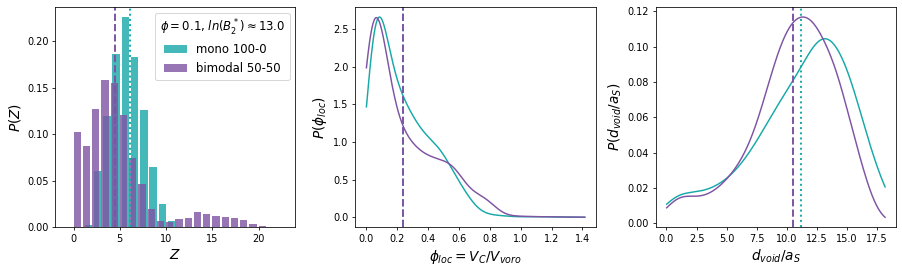

In [27]:
# local packing fraction.
df_d = df_d.copy()
df_d['local_phi'] = (4/3*np.pi*df_d['radius']**3) / df_d['voro_total']

# B2 lookup from phase-data. B2 depends only on (comp, D0),
b2_lookup = (df_all.dropna(subset=['lnB2_ct'])
                   .drop_duplicates(['comp','D0'])
                   .set_index(['comp','D0'])['lnB2_ct'])
def b2_of(comp, D0):
    return float(b2_lookup.loc[(comp, D0)])

# system selectors
def system_final(df, phi, comp, D0):
    sub = df[(df['phi']==phi) & (df['comp']==comp) & (df['D0']==D0)]
    if sub.empty:
        raise ValueError(f"no rows for phi={phi} comp={comp} D0={D0}")
    return sub[sub['frame']==sub['frame'].max()]

def particle_dist(col, phi, comp, D0, typeid=None):
    sub = system_final(df_d, phi, comp, D0)
    if typeid is not None:
        sub = sub[sub['typeid']==typeid]
    a = sub[col].to_numpy(dtype=float)
    return a[np.isfinite(a)]

def void_dist(phi, comp, D0):
    a = system_final(df_void, phi, comp, D0)['void-diameter_G'].to_numpy(dtype=float)
    return a[np.isfinite(a)]


# get mono and bimodal systems with matched B2
df_d25 = df_d.loc[df_d['phi'] == phi_param]
B2 = pd.unique(df_d25['lnB2_round'])[0]
title = f"$\phi=${phi_param}, $ln(B_2^*)\\approx${B2}"
if B2 != B2_param:
    print(f'ERROR: different B2 than expected: {B2} != {B2_param}')
comps = pd.unique(df_d25['comp'])
mono_labels = {'0-100', '100-0'}
mono_comp  = next((c for c in comps if c in mono_labels), None)
bi_comp = next((c for c in comps if c not in mono_labels), None)
if mono_comp == None:
    print(f'ERROR: no monodisperse data in this comparison lnB2={B2}')
if bi_comp == None:
    print(f'ERROR: no bimodal data in this comparison lnB2={B2}')
mono_D0 = pd.unique(df_d25.loc[df_d25['comp'] == mono_comp]['D0'])[0]
bi_D0 = pd.unique(df_d25.loc[df_d25['comp'] == bi_comp]['D0'])[0]

BI_PHI, BI_COMP, BI_D0 = phi_param, bi_comp, bi_D0
MONO_PHI, MONO_COMP, MONO_D0 = phi_param, mono_comp, mono_D0

#### PLOT
panels = [
    ('$Z$',             'particle',  'Z_any'),
    ('$\phi_{loc}=V_{C}/V_{voro}$',  'particle',  'local_phi'),
    ('$d_{void}/a_S$',     'void',       None),
]
fig, axes = plt.subplots(1, 3, figsize=(13,4))
for ax, (lab, src, col) in zip(axes, panels):
    if src == 'particle':
        a_bi   = particle_dist(col, phi_param, BI_COMP,  int(BI_D0))
        a_mono = particle_dist(col, phi_param, MONO_COMP, int(MONO_D0))
    else:
        a_bi   = void_dist(phi_param, BI_COMP,  int(BI_D0))
        a_mono = void_dist(phi_param, MONO_COMP, int(MONO_D0))

    bins = np.histogram_bin_edges(np.concatenate([a_bi, a_mono]), bins=30)
    
    m_c = compositions.index(mono_comp) if mono_comp in compositions else None
    m_color = comp_color_list[m_c]
    m_phi_L = phi_L_vals[m_c]
    
    b_c = compositions.index(bi_comp) if bi_comp in compositions else None
    b_color = comp_color_list[b_c]
    b_phi_L = phi_L_vals[b_c]

    if lab == "$Z$":
        # for the discrete coordination panel, use P(Z) bars instead of a KDE
        vals = np.arange(0, int(max(a_mono.max(), a_bi.max()))+1)
        pm = np.array([(a_mono==v).mean() for v in vals])
        pb = np.array([(a_bi==v).mean()   for v in vals])
        w = 0.8
        ax.bar(vals-w/2, pm, width=w, color=m_color, label=f'mono {MONO_COMP}', alpha=0.8)
        ax.bar(vals+w/2, pb, width=w, color=b_color, label=f'bimodal {BI_COMP}', alpha=0.8)
    else:

        kde_mono = gaussian_kde(a_mono)
        kde_mono.covariance_factor = lambda : .3
        kde_mono._compute_covariance()
        kde_bi = gaussian_kde(a_bi)
        kde_bi.covariance_factor = lambda : .3
        kde_bi._compute_covariance()
        x_values_mono = np.linspace(0, max(bins), len(bins))
        kde_values_mono = kde_mono(x_values_mono)
        x_values_bi = np.linspace(0, max(bins), len(bins))
        kde_values_bi = kde_bi(x_values_bi)
        lo = min(a_mono.min(), a_bi.min())
        hi = max(a_mono.max(), a_bi.max())
        xs = np.linspace(lo, hi, 400)
        ax.plot(xs, kde_mono(xs), color=m_color, label=r'$\mathscr{x}_L=$'+f'{m_phi_L}')
        ax.plot(xs, kde_bi(xs),   color=b_color, label=r'$\mathscr{x}_L=$'+f'{b_phi_L}')

    # mark the means
    ax.axvline(a_mono.mean(), ls=':', lw=2, color=m_color)
    ax.axvline(a_bi.mean(),   ls='--', lw=2, color=b_color)
    ax.set_xlabel(lab, fontsize=14)
    if lab == '$\phi_{loc}=V_{C}/V_{voro}$':
        ax.set_ylabel("$P(\phi_{loc})$",fontsize=14)
    else:
        ax.set_ylabel("$P($"+lab+"$)$",fontsize=14)

axes[0].legend(fontsize=12, title=title, title_fontsize=12)
fig.tight_layout()
plt.show()

#### $\phi = 25$ | *run these cells separately for $ln(B_2^*) = 13$ and $ln(B_2^*) = 30$*


In [28]:
B2_param = 13 #30
phi_param = 0.25
df_d = pd.read_parquet(f'{data_path}/distributions_B2-{B2_param}.0.parquet')
df_d.keys()

Index(['phi', 'comp', 'D0', 'kappa', 'lnB2_round', 'frame', 'particle',
       'radius', 'voro_total', 'Z_any', 'Z_11', 'Z_12', 'Z_21', 'Z_22',
       'Z_1any', 'Z_2any', 'typeid'],
      dtype='object')

In [29]:
df_d25 = df_d.loc[df_d['phi'] == phi_param]
B2 = pd.unique(df_d25['lnB2_round'])[0]
if B2 != B2_param:
    print(f'ERROR: different B2 than expected: {B2} != {B2_param}')
comps = pd.unique(df_d25['comp'])
mono_labels = {'0-100', '100-0'}
mono_comp  = next((c for c in comps if c in mono_labels), None)
bi_comp = next((c for c in comps if c not in mono_labels), None)
if mono_comp == None:
    print(f'ERROR: no monodisperse data in this comparison lnB2={B2}')
if bi_comp == None:
    print(f'ERROR: no bimodal data in this comparison lnB2={B2}')
else:
    print(mono_comp,bi_comp)

100-0 50-50


In [30]:
df_void = pd.read_parquet(f'{data_path}/voidsize_B2-{B2_param}.0.parquet')
df_void.keys()

Index(['phi', 'comp', 'D0', 'kappa', 'lnB2_round', 'frame', 'voidcenter_x',
       'voidcenter_y', 'voidcenter_z', 'void-diameter_G'],
      dtype='object')

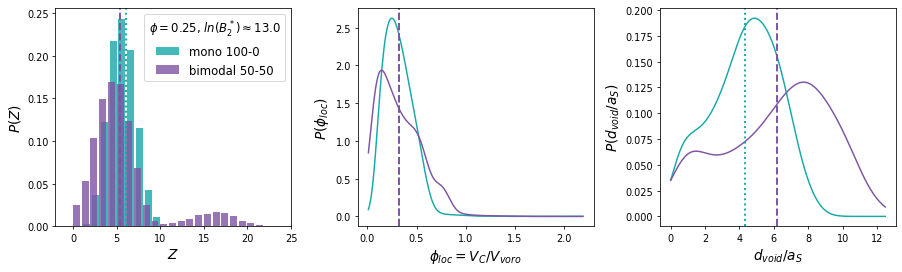

In [31]:
# local packing fraction.
df_d = df_d.copy()
df_d['local_phi'] = (4/3*np.pi*df_d['radius']**3) / df_d['voro_total']

# B2 lookup from phase-data. B2 depends only on (comp, D0),
b2_lookup = (df_all.dropna(subset=['lnB2_ct'])
                   .drop_duplicates(['comp','D0'])
                   .set_index(['comp','D0'])['lnB2_ct'])
def b2_of(comp, D0):
    return float(b2_lookup.loc[(comp, D0)])

# system selectors
def system_final(df, phi, comp, D0):
    sub = df[(df['phi']==phi) & (df['comp']==comp) & (df['D0']==D0)]
    if sub.empty:
        raise ValueError(f"no rows for phi={phi} comp={comp} D0={D0}")
    return sub[sub['frame']==sub['frame'].max()]

def particle_dist(col, phi, comp, D0, typeid=None):
    sub = system_final(df_d, phi, comp, D0)
    if typeid is not None:
        sub = sub[sub['typeid']==typeid]
    a = sub[col].to_numpy(dtype=float)
    return a[np.isfinite(a)]

def void_dist(phi, comp, D0):
    a = system_final(df_void, phi, comp, D0)['void-diameter_G'].to_numpy(dtype=float)
    return a[np.isfinite(a)]


# get mono and bimodal systems with matched B2
df_d25 = df_d.loc[df_d['phi'] == phi_param]
B2 = pd.unique(df_d25['lnB2_round'])[0]
title = f"$\phi=${phi_param}, $ln(B_2^*)\\approx${B2}"
if B2 != B2_param:
    print(f'ERROR: different B2 than expected: {B2} != {B2_param}')
comps = pd.unique(df_d25['comp'])
mono_labels = {'0-100', '100-0'}
mono_comp  = next((c for c in comps if c in mono_labels), None)
bi_comp = next((c for c in comps if c not in mono_labels), None)
if mono_comp == None:
    print(f'ERROR: no monodisperse data in this comparison lnB2={B2}')
if bi_comp == None:
    print(f'ERROR: no bimodal data in this comparison lnB2={B2}')
mono_D0 = pd.unique(df_d25.loc[df_d25['comp'] == mono_comp]['D0'])[0]
bi_D0 = pd.unique(df_d25.loc[df_d25['comp'] == bi_comp]['D0'])[0]

BI_PHI, BI_COMP, BI_D0 = phi_param, bi_comp, bi_D0
MONO_PHI, MONO_COMP, MONO_D0 = phi_param, mono_comp, mono_D0

#### PLOT
panels = [
    ('$Z$',             'particle',  'Z_any'),
    ('$\phi_{loc}=V_{C}/V_{voro}$',  'particle',  'local_phi'),
    ('$d_{void}/a_S$',     'void',       None),
]
fig, axes = plt.subplots(1, 3, figsize=(13,4))
for ax, (lab, src, col) in zip(axes, panels):
    if src == 'particle':
        a_bi   = particle_dist(col, phi_param, BI_COMP,  int(BI_D0))
        a_mono = particle_dist(col, phi_param, MONO_COMP, int(MONO_D0))
    else:
        a_bi   = void_dist(phi_param, BI_COMP,  int(BI_D0))
        a_mono = void_dist(phi_param, MONO_COMP, int(MONO_D0))

    bins = np.histogram_bin_edges(np.concatenate([a_bi, a_mono]), bins=30)
    
    m_c = compositions.index(mono_comp) if mono_comp in compositions else None
    m_color = comp_color_list[m_c]
    m_phi_L = phi_L_vals[m_c]
    
    b_c = compositions.index(bi_comp) if bi_comp in compositions else None
    b_color = comp_color_list[b_c]
    b_phi_L = phi_L_vals[b_c]

    if lab == "$Z$":
        # for the discrete coordination panel, use P(Z) bars instead of a KDE
        vals = np.arange(0, int(max(a_mono.max(), a_bi.max()))+1)
        pm = np.array([(a_mono==v).mean() for v in vals])
        pb = np.array([(a_bi==v).mean()   for v in vals])
        w = 0.8
        ax.bar(vals-w/2, pm, width=w, color=m_color, label=f'mono {MONO_COMP}', alpha=0.8)
        ax.bar(vals+w/2, pb, width=w, color=b_color, label=f'bimodal {BI_COMP}', alpha=0.8)
    else:

        kde_mono = gaussian_kde(a_mono)
        kde_mono.covariance_factor = lambda : .3
        kde_mono._compute_covariance()
        kde_bi = gaussian_kde(a_bi)
        kde_bi.covariance_factor = lambda : .3
        kde_bi._compute_covariance()
        x_values_mono = np.linspace(0, max(bins), len(bins))
        kde_values_mono = kde_mono(x_values_mono)
        x_values_bi = np.linspace(0, max(bins), len(bins))
        kde_values_bi = kde_bi(x_values_bi)
        lo = min(a_mono.min(), a_bi.min())
        hi = max(a_mono.max(), a_bi.max())
        xs = np.linspace(lo, hi, 400)
        ax.plot(xs, kde_mono(xs), color=m_color, label=r'$\mathscr{x}_L=$'+f'{m_phi_L}')
        ax.plot(xs, kde_bi(xs),   color=b_color, label=r'$\mathscr{x}_L=$'+f'{b_phi_L}')

    # mark the means
    ax.axvline(a_mono.mean(), ls=':', lw=2, color=m_color)
    ax.axvline(a_bi.mean(),   ls='--', lw=2, color=b_color)
    ax.set_xlabel(lab, fontsize=14)
    if lab == '$\phi_{loc}=V_{C}/V_{voro}$':
        ax.set_ylabel("$P(\phi_{loc})$",fontsize=14)
    else:
        ax.set_ylabel("$P($"+lab+"$)$",fontsize=14)

axes[0].legend(fontsize=12, title=title, title_fontsize=12)
fig.tight_layout()
plt.show()